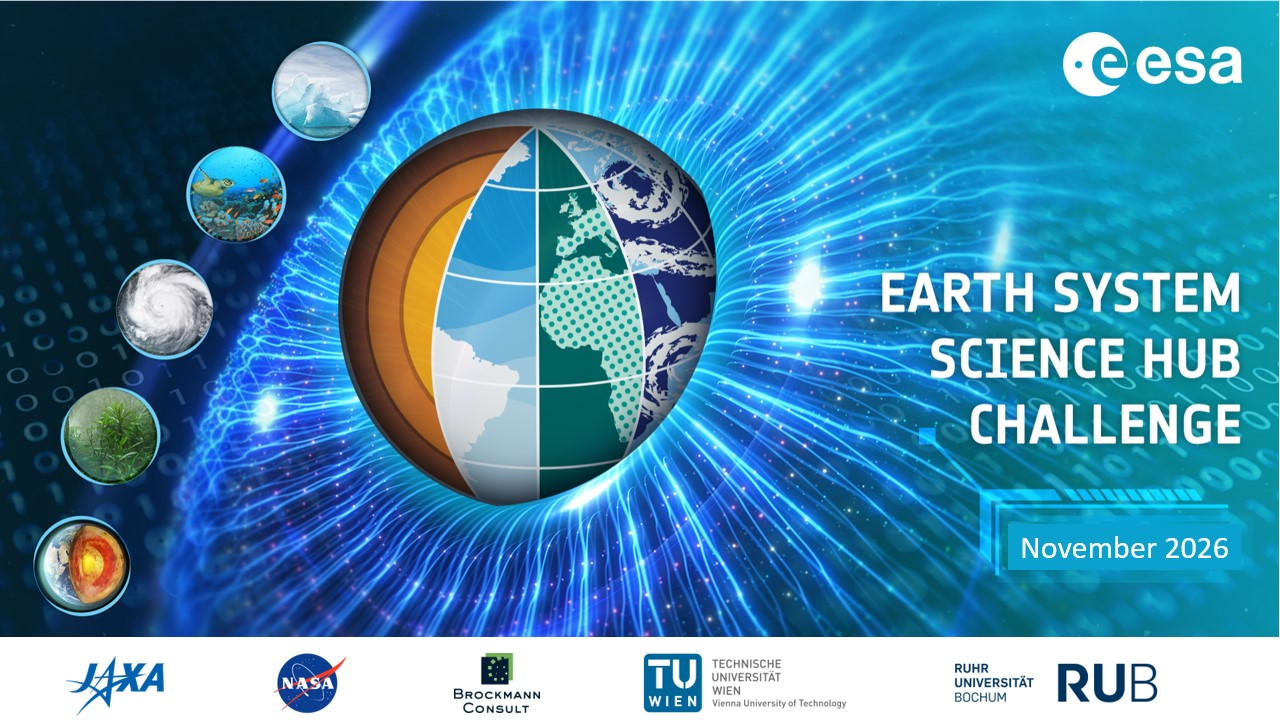

<div class="alert alert-info" role="alert">This concise notebook demonstrates guidelines for submission of your projects developed under the <b>Earth System Science Hub Challenge - 2026!</b><br>
Please use this notebook as a template for delivering your workflow with the code you used to produce the results! 
<br> 
</div>

# PART 1: SUMMARY

<hr>

# <a id='section1'></a><span style='color:DarkCyan'> 1. Vegetation response to atmoshere-ocean circulations </center> </span>
**Author(s):**  Theresa Mimi Freiß, Thomas Himmer, Fabian Unterasinger <br>
**Team name:**  VegetENSO <br>
**Challenge:** Chellenge 4 - Vegetation response to atmoshere-ocean circulations 

# <a id='section2'></a><span style='color:DarkCyan'> 2. Description </center> </span>

### Description of research approach
The goal of the project was to find out if and how ENSO events impact global and regional vegetation. To this end the NOAA RONI Indices was used and compared against GPP, NDVI and NIRV data globally, while being compared only against GPP for three selected regions (parts of Argentina, soutern Africa and Eastern Africa). The analysis was performed on data resampled to monthly results between the period from 2001-01-01 to 2021-12-31, due to availibility.

The methods used were rasterized simple timeseries correlation with timelags ranging from 0-12 months, to determine the lag between highest signal (RONI) and highest absolute response (vegetation indices). 
Furthermore GPP trailing ENSO-events by three months was compared to baseline GPP.



# <a id='section3'></a><span style='color:DarkCyan'> 3. Table of Contents </center> </span> 

 1. [Title](#section1)
 2. [Description](#section2)
 3. [Table of Contents](#section3)
 4. [Import libraries](#section4)
 5. [Access dataset](#section5)
 6. [Analysis cells](#section6)
 7. [ Share the link to your webstory](#section7)

# PART 2: SCIENTIFIC EXPLOITATION AND ANALYSIS

<hr>

# <a id='section4'></a><span style='color:DarkCyan'> 4. Import Libraries </center> </span>

List all libraries necessary to run the script to facilitate the reproducibility! 

In [1]:
# Imports relating to computation
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import gc

import warnings

warnings.filterwarnings(
    "ignore",
    message="Degrees of freedom <= 0 for slice",
    category=RuntimeWarning
)

# Imports relating to plotting
# the esa_sh_helpers folder containing the created submodules has to be present in the current working directory
from esa_sh_helpers.rasterplot import plot_bivariate_raster, plot_raster
# ^ written during ESA Science Hub ^, helps with plotting, submodules were written by a teammember for qa4sm-reader: github: https://github.com/awst-austria/qa4sm-reader Copyright (c) 2019, TU Wien, Department of Geodesy and Geoinformation
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
import os

# <a id='section5'></a><span style='color:DarkCyan'> 5. Data sources </center> </span>

Please update the table with information about dataset used for your specific case. *Table below provides just an example of the available variable description, please update it according to your case study!* <br> 

| Datacube name | Variable name| Description  | Reference* | Region | Time range | Resolution | 
|:--------------------:|:-----------------------:|:-------------:|:-----------------:|:-----------------:|:-----------------:|:-----------------:|
| ESDC | gross_primary_productivity | <a href="https://www.fluxcom.org/CF-Products/#evaluation-of-global-patterns-of-gpp" target="_blank">FLUXCOM Gross Primary Productivity (GPP)</a> | <a href="https://www.fluxcom.org/CF-Products/#evaluation-of-global-patterns-of-gpp" target="_blank">link to source</a> | Global | 2001–2020 (8-day) | 0.0833° / 0.25° | <br>
| ESDC | ndvi | <a href="https://earthsystemdatalab.net/index.php/data-cube/" target="_blank">Normalized Difference Vegetation Index (NDVI)</a> | <a href="https://lpdaac.usgs.gov/products/mcd43c4v061/" target="_blank">link to source</a> | Global | 1981–2020 (8-day / 16-day) | 0.0833° / 0.25° | <br>
| ESDC | nirv | <a href="https://earthsystemdatalab.net/index.php/data-cube/" target="_blank">Near-Infrared Reflectance of Vegetation (NIRv)</a> | <a href="https://lpdaac.usgs.gov/products/mcd43c4v061/" target="_blank">link to source</a> | Global | 2000–2020 (8-day / monthly) | 0.0833° / 0.25° | <br>
| NOAA CPC / PSL | RONI | <a href="https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/ensostuff/ONI_v5.php" target="_blank">Relative Oceanic Niño Index (RONI)</a> | <a href="https://www.cpc.ncep.noaa.gov/data/indices/RONI.ascii.txt" target="_blank">link to source</a> | Global | 1950–present (monthly) | 1D time series | <br>

**IMPORTANT**: In case your dataset is **not** incorporated in `sciencehub-challenges-input-data` folder:
- Save the dataset in shared directory: e.g. `sciencehub-challenges-user-data/processing/[team-id]/data/`.
- Indicate the location of your dataset in these other repository by updating* <b> Reference</b> *field*.



**Provide a code section on data access in the cell(s) below**

In [2]:
# Data Access is done through the individual functions in the following section

# <a id='section6'></a><span style='color:DarkCyan'> 6. Analysis cells </center> </span> 


## Calculation

### Settings

In [3]:
OUTPUT_DIR = Path(f"results/final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# RONI index settings:
RONI_FILE = Path("/shared/.sciencehub-challenges-2026-11-user-data/processing/team-4/data/NOOA RONI data/RONI.ascii.txt")
START, END = "2001-01-01", "2021-12-31"
MAX_LAG = 12         # Positive lag = RONI leads vegetation by N months
MIN_VALID_MONTHS = 120
ALPHA = 0.05

# RONI phase settings:
PHASES = ("el_nino", "la_nina")
PHASE_LABELS = {"el_nino": "El Niño", "la_nina": "La Niña"}
THRESHOLD = 0.5
MIN_DURATION = 5
MIN_PHASE_PAIRS = 24
COMPOSITE_LAG = 3  # fixed, prespecified lag for ENSO/neutral composites

### Workflow and helper functions

In [4]:
# -----------------------------------------------------------------------------
# 1. Read RONI (three-month seasons are assigned to their center month)
# -----------------------------------------------------------------------------
def load_roni(path):
    """Read NOAA RONI ASCII table and return a monthly-indexed DataArray.

    Three-month seasonal averages (e.g., DJF, JFM) are mapped to their
    central calendar month (MS frequency).

    Parameters
    ----------
    path : str or pathlib.Path
        File path to the whitespace-delimited RONI data file containing
        `YR`, `SEAS`, and `ANOM` columns.

    Returns
    -------
    xr.DataArray
        1D float DataArray named `"RONI"` indexed by monthly start dates (`time`).
    """
    df = pd.read_csv(path, sep=r"\s+")
    season_to_month = {
        "DJF": 1, "JFM": 2, "FMA": 3, "MAM": 4,
        "AMJ": 5, "MJJ": 6, "JJA": 7, "JAS": 8,
        "ASO": 9, "SON": 10, "OND": 11, "NDJ": 12,
    }
    df["month"] = df["SEAS"].map(season_to_month)
    df["time"] = pd.to_datetime(dict(year=df["YR"], month=df["month"], day=1))
    df = df.set_index("time").sort_index().asfreq("MS")
    return xr.DataArray(
        df["ANOM"].to_numpy(dtype=float),
        dims="time", coords={"time": df.index}, name="RONI",
    )


# -----------------------------------------------------------------------------
# 2. Read a single ESDC vegetation variable, coarsen and aggregate monthly
# -----------------------------------------------------------------------------
def load_monthly_vegetation(variable, bbox=None):
    """Load an Earth System Data Cube (ESDC) vegetation variable, optionally
    subset and spatially coarsen it, and aggregate to monthly means.

    Parameters
    ----------
    variable : str
        Name of the variable in the public ESDC Zarr store
        (`esdc-8d-0.25deg-1x720x1440-3.0.1.zarr`).
    bbox : dict, optional
        Spatial bounding box with keys `"lon"` and `"lat"`, each mapping to a
        `(min, max)` sequence. If None, loads the global domain.

    Returns
    -------
    xr.DataArray
        Materialized 3D (`time`, `lat`, `lon`) monthly mean DataArray sliced
        between global constants `START` and `END`.
    """
    from xcube.core.store import new_data_store

    store = new_data_store(
        "s3", root="deep-esdl-public", storage_options=dict(anon=True)
    )
    data = store.open_data("esdc-8d-0.25deg-1x720x1440-3.0.1.zarr")
    if variable not in data:
        raise KeyError(f"ESDC variable not found: {variable}")

    da = data[variable].sel(time=slice(START, END))

    # Spatial subset before processing
    if bbox is not None:
        lon_min, lon_max = bbox["lon"]
        lat_min, lat_max = bbox["lat"]

        # Account for latitude coordinate ordering
        lat_slice = (
            slice(lat_min, lat_max)
            if da.lat.values[0] < da.lat.values[-1]
            else slice(lat_max, lat_min)
        )

        da = da.sel(
            lon=slice(lon_min, lon_max),
            lat=lat_slice,
        )
    
    # Spatial aggregation (skip at native resolution)
    if SPATIAL_FACTOR > 1:
        da = da.coarsen(
            lat=SPATIAL_FACTOR,
            lon=SPATIAL_FACTOR,
            boundary="trim"
        ).mean(skipna=True)

    da = da.resample(time="MS").mean(skipna=True)

    # Materialize only the coarse monthly product; subsequent steps are local.
    from dask.diagnostics import ProgressBar
    with ProgressBar():
        da = da.load()
    return da


# -----------------------------------------------------------------------------
# 3. Remove mean seasonal cycle and linear trend at each grid cell
# -----------------------------------------------------------------------------
def vegetation_anomalies(monthly):
    """Deseasonalize and linearly detrend a monthly vegetation DataArray per grid cell.

    Subtracts the climatological monthly cycle and removes the ordinary least-squares
    linear trend over valid time steps. Cells failing minimum sample count
    (`MIN_VALID_MONTHS`) or minimum temporal standard deviation (`1e-6`) are masked.

    Parameters
    ----------
    monthly : xr.DataArray
        Monthly vegetation time series with a `"time"` dimension.

    Returns
    -------
    xr.DataArray
        Deseasonalized, detrended anomaly DataArray with low-coverage or
        invariant cells masked as NaN.
    """
    seasonal_mean = monthly.groupby("time.month").mean("time", skipna=True)
    anom = monthly.groupby("time.month") - seasonal_mean

    time_index = xr.DataArray(
        np.arange(anom.sizes["time"], dtype=float),
        dims="time", coords={"time": anom.time},
    )

    valid = anom.notnull()
    centered_time = time_index - time_index.where(valid).mean("time")
    centered_anom = anom - anom.mean("time", skipna=True)

    slope = (
        (centered_time * centered_anom).sum("time", skipna=True)
        / (centered_time**2).where(valid).sum("time", skipna=True)
    )
    anom = centered_anom - slope * centered_time

    # Do not mask low-NDVI drylands: many have large ENSO responses.
    enough_data = monthly.count("time") >= MIN_VALID_MONTHS
    has_variability = anom.std("time", skipna=True) > 1e-6
    return anom.where(enough_data & has_variability)


# -----------------------------------------------------------------------------
# 4. Calculate r for each positive lag and identify the strongest response
# -----------------------------------------------------------------------------
def lagged_correlations(veg_anom, roni):
    """Compute lagged Pearson correlations between vegetation anomalies and RONI,
    select the strongest lag per grid cell, and estimate FDR-adjusted significance.

    Evaluates lags `0..MAX_LAG` (RONI leading vegetation), selects the lag maximizing
    `|r|`, adjusts degrees of freedom via AR(1) autocorrelation, and applies
    Bonferroni (across lags) and Benjamini–Hochberg (across space) corrections.

    Parameters
    ----------
    veg_anom : xr.DataArray
        Deseasonalized, detrended monthly vegetation anomalies.
    roni : xr.DataArray
        Monthly RONI time series.

    Returns
    -------
    xr.Dataset
        Dataset containing `r_best`, `lag_best`, `n_pairs`, `n_eff`, `p_fdr`,
        boolean `significant` mask (`p_fdr < ALPHA`), and full `r_by_lag`.
    """
    lags = np.arange(MAX_LAG + 1)
    roni_lagged = [roni.shift(time=int(k)).reindex(time=veg_anom.time) for k in lags]

    r_all = xr.concat(
        [xr.corr(veg_anom, shifted_roni, dim="time") for shifted_roni in roni_lagged],
        dim=xr.IndexVariable("lag", lags),
    )
    n_all = xr.concat(
        [(veg_anom.notnull() & x.notnull()).sum("time") for x in roni_lagged],
        dim=xr.IndexVariable("lag", lags),
    )

    any_valid = r_all.notnull().any("lag")
    lag_index = np.abs(r_all).fillna(-1).argmax("lag")
    best_r = r_all.isel(lag=lag_index).drop_vars("lag").where(any_valid)
    best_lag = r_all.lag.isel(lag=lag_index).where(any_valid)
    best_n = n_all.isel(lag=lag_index).drop_vars("lag").where(any_valid)

    # Exploratory significance approximation: AR(1) effective sample size.
    veg_ar1 = xr.corr(veg_anom, veg_anom.shift(time=1), dim="time")
    roni_now = roni.reindex(time=veg_anom.time)
    roni_prev = roni.shift(time=1).reindex(time=veg_anom.time)
    roni_ar1 = xr.corr(roni_now, roni_prev, dim="time")
    ar_product = veg_ar1 * roni_ar1
    n_eff = best_n * (1 - ar_product) / (1 + ar_product)
    n_eff = n_eff.clip(min=3)
    n_eff = xr.where(n_eff > best_n, best_n, n_eff)

    dfree = n_eff - 2
    t_stat = np.abs(best_r) * np.sqrt(dfree / (1 - best_r**2).clip(min=1e-12))
    p_raw = xr.apply_ufunc(lambda t, d: 2 * stats.t.sf(t, d), t_stat, dfree)

    # Correct selection over 0..MAX_LAG (Bonferroni), then across spatial cells (BH).
    p_lags = (p_raw * len(lags)).clip(max=1)
    p_fdr = benjamini_hochberg(p_lags)

    return xr.Dataset(
        {
            "r_best": best_r.astype("float32"),
            "lag_best": best_lag.astype("float32"),
            "n_pairs": best_n.astype("float32"),
            "n_eff": n_eff.astype("float32"),
            "p_fdr": p_fdr.astype("float32"),
            "significant": (p_fdr < ALPHA),
            "r_by_lag": r_all.astype("float32"),
        }
    )


def benjamini_hochberg(p_map):
    """Apply Benjamini–Hochberg false discovery rate (FDR) correction across all
    finite elements of `p_map`, preserving missing (NaN) grid cells.

    Parameters
    ----------
    p_map : xr.DataArray
        Array of raw or lag-adjusted p-values.

    Returns
    -------
    xr.DataArray
        DataArray of the same shape and coordinates with FDR-adjusted q-values
        clipped to `[0, 1]`.
    """
    p = np.asarray(p_map.values, dtype=float)
    good = np.isfinite(p)
    values = p[good]
    adjusted = np.full(p.shape, np.nan)
    if values.size:
        order = np.argsort(values)
        sorted_q = values[order] * values.size / np.arange(1, values.size + 1)
        sorted_q = np.minimum.accumulate(sorted_q[::-1])[::-1]
        q_values = np.empty_like(values)
        q_values[order] = np.clip(sorted_q, 0, 1)
        adjusted[good] = q_values
    return p_map.copy(data=adjusted)

def identify_events(condition, min_duration=MIN_DURATION):
    """Flag contiguous runs where a boolean condition holds for at least `min_duration` steps.

    Parameters
    ----------
    condition : pd.Series
        Boolean time series indicating threshold exceedance.
    min_duration : int, optional
        Minimum consecutive time steps required to qualify as a valid event,
        by default `MIN_DURATION`.

    Returns
    -------
    pd.Series
        Boolean Series that is True only during qualifying contiguous runs.
    """
    condition = condition.fillna(False)
    groups = condition.ne(condition.shift()).cumsum()
    duration = condition.groupby(groups).transform("size")
    return condition & (duration >= min_duration)


def classify_roni(roni):
    """Classify the full RONI time series into ENSO phases and assign unique event IDs.

    Must be run on the complete RONI record before slicing or lag-shifting so event
    durations at boundaries are preserved. Months with `|RONI| < THRESHOLD` are
    labeled `'neutral'`; runs exceeding `±THRESHOLD` for at least `MIN_DURATION`
    months are labeled `'el_nino'` or `'la_nina'`; shorter threshold exceedances
    are labeled `'other'` and excluded from phase composites.

    Parameters
    ----------
    roni : xr.DataArray
        Monthly RONI DataArray.

    Returns
    -------
    pd.DataFrame
        Monthly DataFrame indexed by `time` with columns `ANOM`, `el_nino`,
        `la_nina`, `phase`, and `event_id`.
    """
    df = roni.to_series().rename("ANOM").to_frame().asfreq("MS")
    df["el_nino"] = identify_events(df["ANOM"] >= THRESHOLD)
    df["la_nina"] = identify_events(df["ANOM"] <= -THRESHOLD)

    df["phase"] = np.select(
        [df.el_nino, df.la_nina, df.ANOM.abs() < THRESHOLD],
        ["el_nino", "la_nina", "neutral"],
        default="other",
    )
    df.loc[df.ANOM.isna(), "phase"] = "missing"

    # Unique ID for each contiguous El Niño / La Niña event.
    runs = df.phase.ne(df.phase.shift()).cumsum()
    df["event_id"] = np.where(df.phase.isin(PHASES), runs, np.nan)
    return df

def _aligned_classification(classes, veg_time, lag):
    """Shift ENSO phase and event ID labels forward by `lag` months and align to `veg_time`.

    Tags vegetation at time `t` with the ENSO phase and event ID active at `t - lag`.

    Parameters
    ----------
    classes : pd.DataFrame
        Output DataFrame from `classify_roni` containing `phase` and `event_id`.
    veg_time : xr.DataArray or pd.DatetimeIndex
        Target time coordinate of the vegetation dataset.
    lag : int
        Positive lag in months by which RONI leads vegetation.

    Returns
    -------
    tuple[xr.DataArray, xr.DataArray]
        Tuple of `(phase, event_id)` DataArrays aligned to `veg_time`.
    """
    phase_da = xr.DataArray(
        classes.phase.to_numpy(), dims="time", coords={"time": classes.index}
    )
    event_da = xr.DataArray(
        classes.event_id.to_numpy(dtype=float),
        dims="time", coords={"time": classes.index},
    )
    phase = phase_da.shift(time=lag).reindex(time=veg_time)
    event_id = event_da.shift(time=lag).reindex(time=veg_time)
    return phase, event_id


def phase_lagged_correlations(veg_anom, roni, classes,
                              max_lag=MAX_LAG,
                              min_pairs=MIN_PHASE_PAIRS):
    """Compute pooled-month correlations within each ENSO phase across lags `0..max_lag`.

    Shifts RONI and phase classifications first before masking by phase so lag
    alignment across event boundaries remains intact. P-values are omitted because
    selected months are serially dependent and optimal lags are selection-biased.

    Parameters
    ----------
    veg_anom : xr.DataArray
        Deseasonalized, detrended monthly vegetation anomalies.
    roni : xr.DataArray
        Monthly RONI DataArray.
    classes : pd.DataFrame
        Output DataFrame from `classify_roni`.
    max_lag : int, optional
        Maximum lag in months to evaluate, by default `MAX_LAG`.
    min_pairs : int, optional
        Minimum valid paired months required per phase and lag, by default `MIN_PHASE_PAIRS`.

    Returns
    -------
    xr.Dataset
        Dataset dimensioned by `phase` (and `lag`) containing `r_by_lag`,
        `n_by_lag`, `r_best`, `lag_best`, and `n_pairs_best`.
    """
    lags = np.arange(max_lag + 1)
    r_per_phase, n_per_phase = [], []

    for name in PHASES:
        correlations, counts = [], []
        for k in lags:
            shifted_roni = roni.shift(time=int(k)).reindex(time=veg_anom.time)
            shifted_phase, _ = _aligned_classification(classes, veg_anom.time, int(k))
            valid = (
                (shifted_phase == name)
                & veg_anom.notnull()
                & shifted_roni.notnull()
            )
            n = valid.sum("time")
            r = xr.corr(
                veg_anom.where(valid), shifted_roni.where(valid), dim="time"
            ).where(n >= min_pairs)
            correlations.append(r)
            counts.append(n)

        r_per_phase.append(xr.concat(correlations, dim=xr.IndexVariable("lag", lags)))
        n_per_phase.append(xr.concat(counts, dim=xr.IndexVariable("lag", lags)))

    r_by_lag = xr.concat(r_per_phase, dim=xr.IndexVariable("phase", list(PHASES)))
    n_by_lag = xr.concat(n_per_phase, dim=xr.IndexVariable("phase", list(PHASES)))
    any_valid = r_by_lag.notnull().any("lag")
    best_idx = np.abs(r_by_lag).fillna(-1).argmax("lag")

    return xr.Dataset({
        "r_by_lag": r_by_lag.astype("float32"),
        "n_by_lag": n_by_lag.astype("int32"),
        "r_best": (
            r_by_lag.isel(lag=best_idx).drop_vars("lag", errors="ignore")
            .where(any_valid).astype("float32")
        ),
        "lag_best": r_by_lag.lag.isel(lag=best_idx).where(any_valid).astype("float32"),
        "n_pairs_best": (
            n_by_lag.isel(lag=best_idx).drop_vars("lag", errors="ignore")
            .where(any_valid).astype("float32")
        ),
    })


def event_weighted_composites(veg_anom, classes, lag=COMPOSITE_LAG):
    """Compute equal-weighted event-mean vegetation anomalies per ENSO phase at a fixed lag.

    Averages vegetation anomalies within each distinct ENSO event first so long-lasting
    events do not dominate the composite, then averages across events (requiring at
    least 3 valid events per grid cell). Neutral baseline uses the pooled mean at `lag`.

    Parameters
    ----------
    veg_anom : xr.DataArray
        Deseasonalized, detrended monthly vegetation anomalies.
    classes : pd.DataFrame
        Output DataFrame from `classify_roni`.
    lag : int, optional
        Lag in months by which ENSO phase leads vegetation anomalies,
        by default `COMPOSITE_LAG`.

    Returns
    -------
    xr.Dataset
        Dataset containing `phase_event_mean`, `neutral_mean`,
        `phase_minus_neutral`, and `n_events_with_data`.
    """
    shifted_phase, shifted_id = _aligned_classification(classes, veg_anom.time, lag)
    neutral = veg_anom.where(shifted_phase == "neutral").mean("time", skipna=True)
    phase_means, event_counts = [], []

    for name in PHASES:
        # Restrict event IDs to those that actually overlap the vegetation record.
        ids = np.unique(shifted_id.where(shifted_phase == name).values)
        ids = ids[np.isfinite(ids)]
        if len(ids) == 0:
            raise ValueError(f"No classified {name} events in the RONI file")
        event_means = xr.concat(
            [veg_anom.where(shifted_id == eid).mean("time", skipna=True) for eid in ids],
            dim=xr.IndexVariable("event", np.arange(len(ids))),
        )
        phase_means.append(event_means.mean("event", skipna=True))
        event_counts.append(event_means.notnull().sum("event"))

    mean_ens = xr.concat(phase_means, dim=xr.IndexVariable("phase", list(PHASES)))
    n_events = xr.concat(event_counts, dim=xr.IndexVariable("phase", list(PHASES)))
    mean_ens = mean_ens.where(n_events >= 3)
    return xr.Dataset({
        "phase_event_mean": mean_ens.astype("float32"),
        "neutral_mean": neutral.astype("float32"),
        "phase_minus_neutral": (mean_ens - neutral).astype("float32"),
        "n_events_with_data": n_events.astype("int16"),
    })

### Run processing workflow:

In [5]:
regions = {
    "global" : None,  # no bbox for global,
    "East-Africa": {"lon": (30, 52), "lat": (-6, 13)},
    "South-Africa": {"lon": (10, 42), "lat": (-40, -10)},
    "Argentina": {"lon": (-70, -50), "lat": (-50, -20)}
}

for region, bbox in regions.items():
    print(f"Processing {region}")

    if region=="global":
        SPATIAL_FACTOR = 4
        VARIABLES = ["gpp", "nirv", "ndvi"]
    else:
        SPATIAL_FACTOR = 1
        VARIABLES = ["gpp"]

    for VARIABLE in VARIABLES:
        # full name for gpp
        VARIABLE_full = "gross_primary_productivity" if VARIABLE=="gpp" else VARIABLE

        # -------------- RONI-Vegetation comparison --------------
        
        roni = load_roni(RONI_FILE)
        monthly = load_monthly_vegetation(VARIABLE_full, bbox=bbox)
        veg_anom = vegetation_anomalies(monthly)
        results = lagged_correlations(veg_anom, roni)
        
        results.attrs.update(
            variable=VARIABLE,
            spatial_resolution_deg=0.25 * SPATIAL_FACTOR,
            time_period=f"{START} to {END}",
            max_lag_months=MAX_LAG,
            lag_convention="positive lag means RONI leads vegetation",
            significance="approximate AR1 n_eff; Bonferroni over lags; BH across grid cells",
        )
        
        output_nc = OUTPUT_DIR / f"{region}_{VARIABLE}_R+lag.nc"
        results.to_netcdf(output_nc)
        
        print(f"Saved results: {output_nc}")
        
        # Free memory
        del results
        gc.collect()
    
        # -------------- PHASE specific comparison --------------
    
        classes = classify_roni(roni)
        print("Classified ENSO events overlapping the vegetation study period:")
        shifted_phase, shifted_id = _aligned_classification(
            classes, pd.date_range(START, END, freq="MS"), 0
        )
        for name in PHASES:
            ids = np.unique(shifted_id.where(shifted_phase == name).values)
            n = np.isfinite(ids).sum()
            print(f"  {PHASE_LABELS[name]}: {n}")
        
        corr = phase_lagged_correlations(veg_anom, roni, classes)
        composites = event_weighted_composites(veg_anom, classes)
        results = xr.merge([corr, composites])
        results.attrs.update(
            variable=VARIABLE,
            units=monthly.attrs.get("units", ""),
            analysis_period=f"{START} to {END}",
            min_phase_pairs=MIN_PHASE_PAIRS,
            max_lag_months=MAX_LAG,
            composite_lag_months=COMPOSITE_LAG,
            classification=(
                "El Niño RONI>=0.5 / La Niña RONI<=-0.5 for >=5 consecutive "
                "3-month seasons; neutral |RONI|<0.5; shorter excursions omitted"
            ),
            lag_convention="positive lag: RONI at t-lag correlated with VI at t",
            caution=(
                "Pooled-month phase correlations; no inferential p values. "
                "Composite anomalies average classified ENSO events equally."
            ),
        )

        OUTFILE = OUTPUT_DIR / f"{region}_{VARIABLE}_phases.nc"
        results.to_netcdf(OUTFILE)
        print(f"Saved: {OUTFILE}")

        # Free memory
        del monthly, veg_anom, results, corr, composites
        gc.collect()

Processing global
[########################################] | 100% Completed | 76.65 s
Saved results: results/final/global_gpp_R+lag.nc
Classified ENSO events overlapping the vegetation study period:
  El Niño: 6
  La Niña: 9
Saved: results/final/global_gpp_phases.nc
[########################################] | 100% Completed | 77.34 s


/home/conda/global/35c222ea-1792597853-7-deepesdl-xcube-1.13.1/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


Saved results: results/final/global_nirv_R+lag.nc
Classified ENSO events overlapping the vegetation study period:
  El Niño: 6
  La Niña: 9
Saved: results/final/global_nirv_phases.nc
[########################################] | 100% Completed | 79.91 s


/home/conda/global/35c222ea-1792597853-7-deepesdl-xcube-1.13.1/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/home/conda/global/35c222ea-1792597853-7-deepesdl-xcube-1.13.1/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


Saved results: results/final/global_ndvi_R+lag.nc
Classified ENSO events overlapping the vegetation study period:
  El Niño: 6
  La Niña: 9
Saved: results/final/global_ndvi_phases.nc
Processing East-Africa
[########################################] | 100% Completed | 69.71 s
Saved results: results/final/East-Africa_gpp_R+lag.nc
Classified ENSO events overlapping the vegetation study period:
  El Niño: 6
  La Niña: 9
Saved: results/final/East-Africa_gpp_phases.nc
Processing South-Africa
[########################################] | 100% Completed | 50.80 s
Saved results: results/final/South-Africa_gpp_R+lag.nc
Classified ENSO events overlapping the vegetation study period:
  El Niño: 6
  La Niña: 9
Saved: results/final/South-Africa_gpp_phases.nc
Processing Argentina
[########################################] | 100% Completed | 44.16 s
Saved results: results/final/Argentina_gpp_R+lag.nc
Classified ENSO events overlapping the vegetation study period:
  El Niño: 6
  La Niña: 9
Saved: result

## Plotting

In [6]:
plot_folder = "plots"
if not os.path.exists(f"{plot_folder}/"):
    os.makedirs(f"{plot_folder}")

### RONI Timeseries with marked ENSO-Events (one plot per metric)

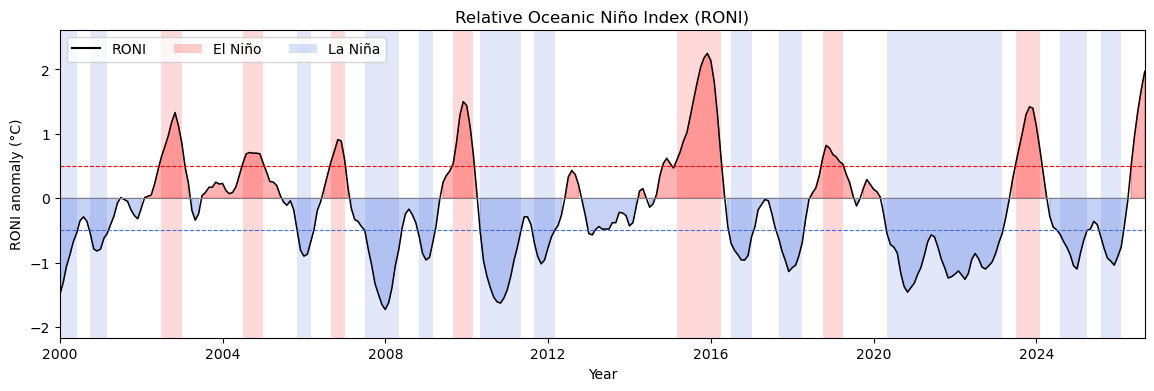

In [7]:
df = pd.read_csv(RONI_FILE, sep=r"\s+")

season_to_month = {
    "DJF": 1, "JFM": 2, "FMA": 3, "MAM": 4,
    "AMJ": 5, "MJJ": 6, "JJA": 7, "JAS": 8,
    "ASO": 9, "SON": 10, "OND": 11, "NDJ": 12,
}

df["month"] = df["SEAS"].map(season_to_month)

df["time"] = pd.to_datetime(
    dict(year=df["YR"], month=df["month"], day=1)
)

df = df.set_index("time").sort_index()

# --------------------------------------------------
# Identify ENSO events
# --------------------------------------------------

threshold = 0.5
min_duration = 5

# Reindex to monthly frequency to ensure that missing months
# do not count as consecutive seasons
df = df.asfreq("MS")

def identify_events(condition, min_duration=5):
    # Identify consecutive runs of True/False
    groups = condition.ne(condition.shift()).cumsum()

    # Length of each consecutive run
    duration = condition.groupby(groups).transform("size")

    return condition & (duration >= min_duration)

df["el_nino"] = identify_events(
    df["ANOM"] >= threshold, min_duration
)
df["la_nina"] = identify_events(
    df["ANOM"] <= -threshold, min_duration
)

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(
    df.index,
    df["ANOM"],
    color="black",
    linewidth=1.1,
    label="RONI",
)

ax.fill_between(
    df.index, df["ANOM"], 0,
    where=df["ANOM"] >= 0,
    color="red", alpha=0.3,
)
ax.fill_between(
    df.index, df["ANOM"], 0,
    where=df["ANOM"] < 0,
    color="royalblue", alpha=0.3,
)

# Highlight El Niño and La Niña periods
for column, color in [
    ("el_nino", "red"),
    ("la_nina", "royalblue"),
]:
    ax.fill_between(
        df.index,
        0, 1,
        where=df[column],
        color=color,
        alpha=0.15,
        step="mid",
        transform=ax.get_xaxis_transform(),
        edgecolor=None
    )

# Reference lines
ax.axhline(0, color="gray", linewidth=0.8)
ax.axhline(0.5, color="red", linestyle="--", linewidth=0.8)
ax.axhline(-0.5, color="royalblue", linestyle="--", linewidth=0.8)

# Legend
handles = [
    plt.Line2D([], [], color="black", label="RONI"),
    Patch(facecolor="red", alpha=0.2, label="El Niño"),
    Patch(facecolor="royalblue", alpha=0.2, label="La Niña"),
]

ax.legend(handles=handles, loc="upper left", ncol=3)

ax.set(
    title="Relative Oceanic Niño Index (RONI)",
    xlabel="Year",
    ylabel="RONI anomaly (°C)",
)
ax.set_xlim(pd.Timestamp("2000-01-01"), df.index.max())

plt.savefig(f"{plot_folder}/RONI.png", dpi=100, bbox_inches="tight")

### GLOBAL: Bivariate Time-Lagged Fit between Veg_Ind and RONI (one plot per metric)

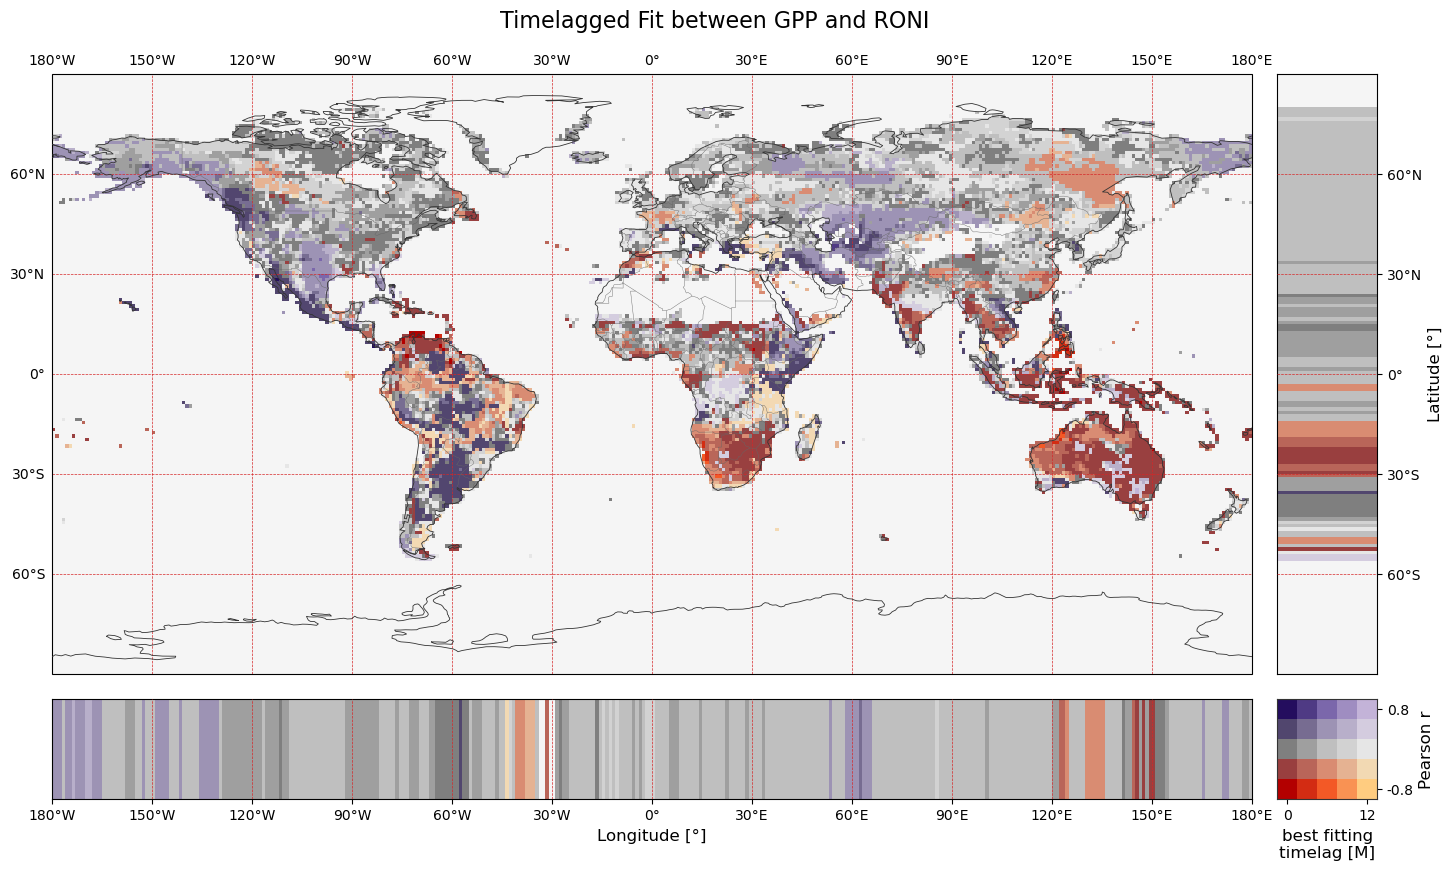

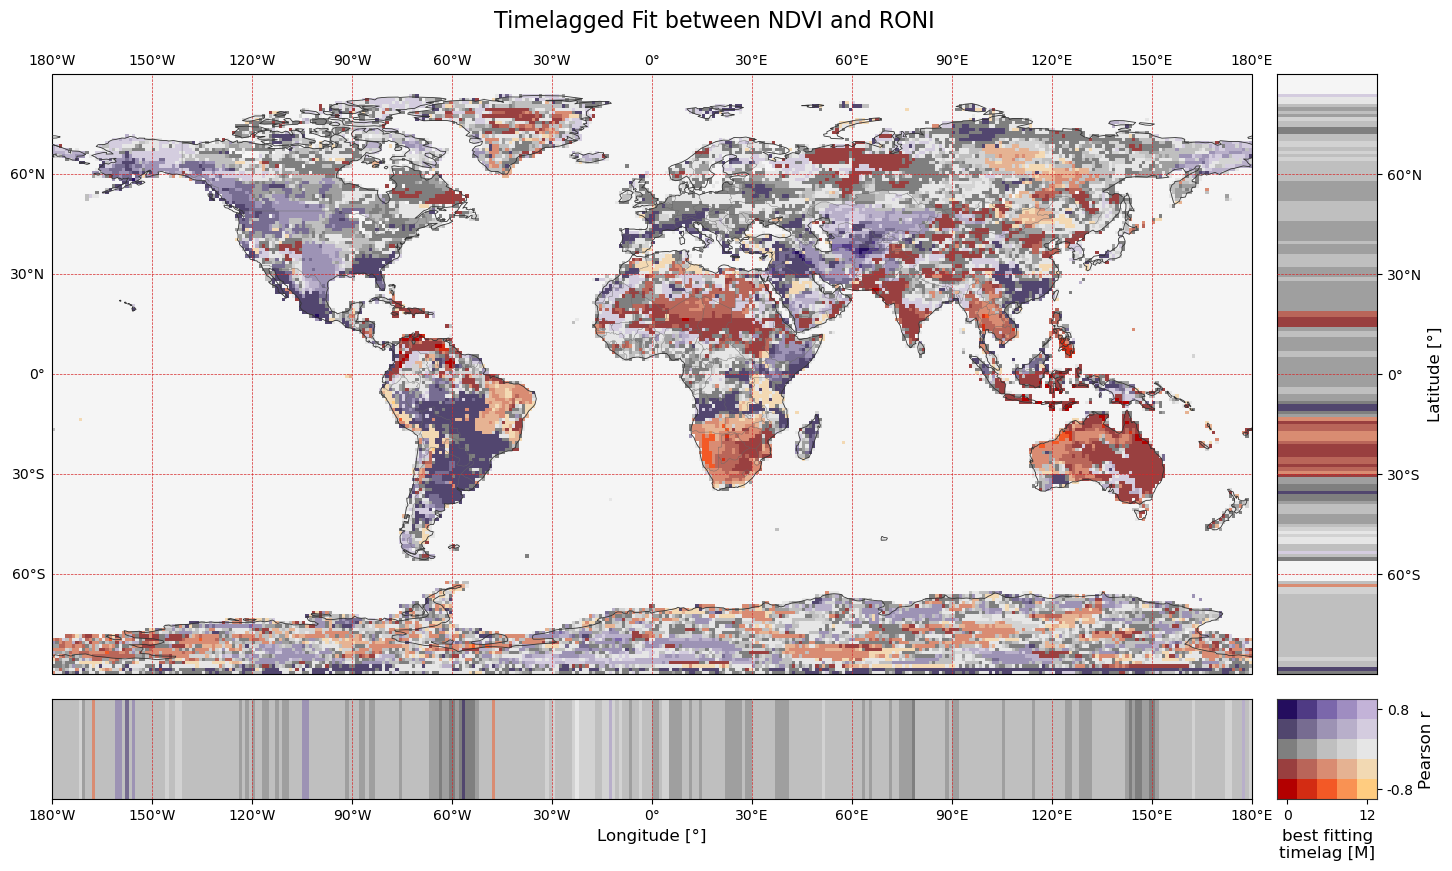

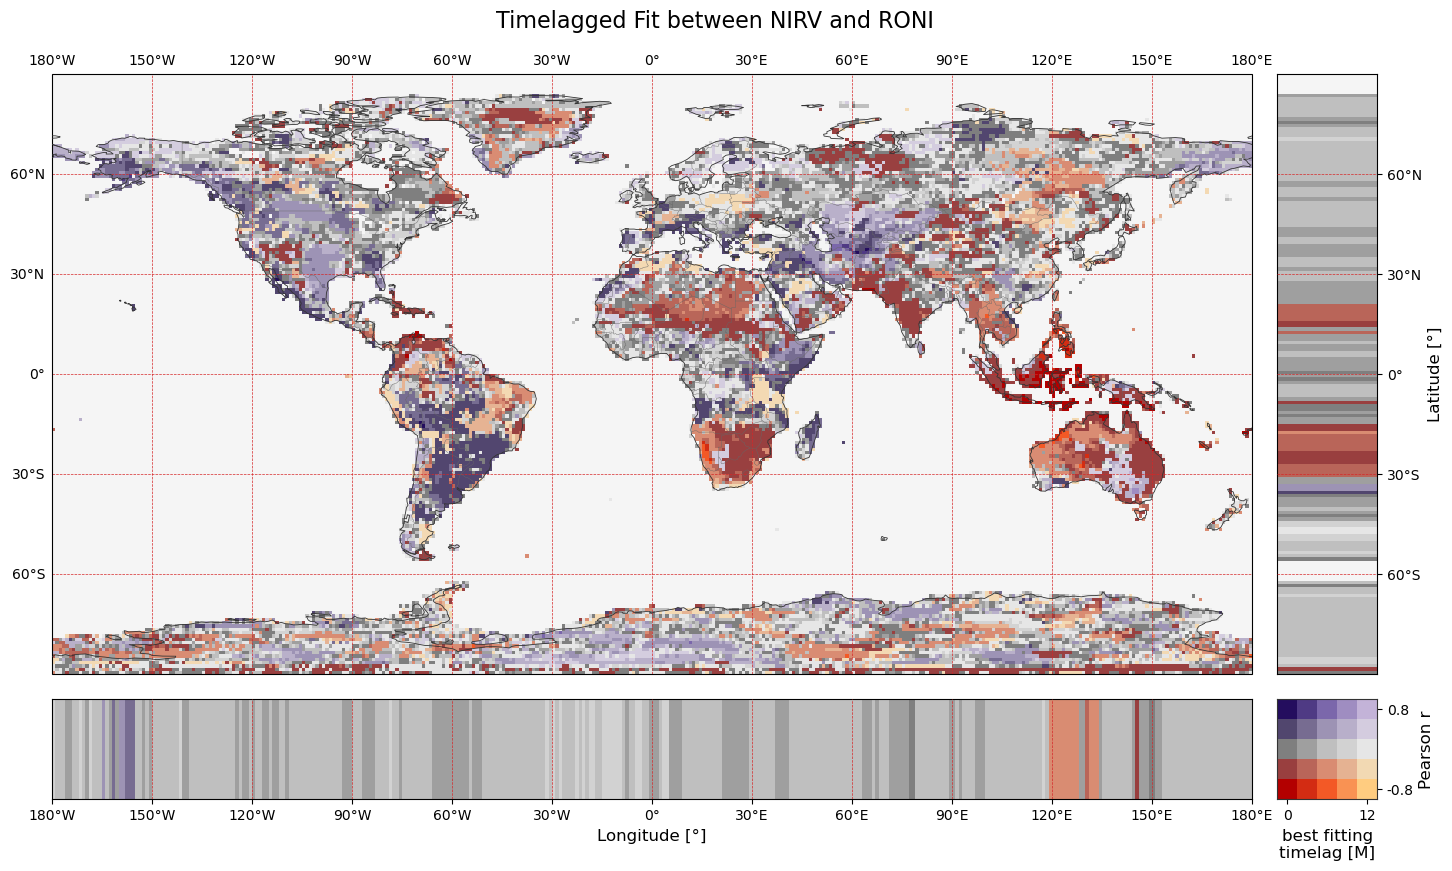

In [8]:
data_folder = "results/final" # Folder einfügen
names = ["global_gpp_R+lag", "global_ndvi_R+lag", "global_nirv_R+lag"]
metrics = ["GPP", "NDVI", "NIRV"]
subfolder = "lag"
if not os.path.exists(f"{plot_folder}/{subfolder}/"):
    os.makedirs(f"{plot_folder}/{subfolder}")
for i, name in enumerate(names):
    ds = xr.open_dataset(f"{data_folder}/{name}.nc")
    fig, ax, legend = plot_bivariate_raster(ds=ds, 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/{name}.png", dpi=100)

### GLOBAL: Bivariate Time-Lagged Fit between Veg_Ind and RONI per ENSO-Phase (two plots per metric) & Veg_Ind Anomalies between baseline and ENSO event (two plots per metric)

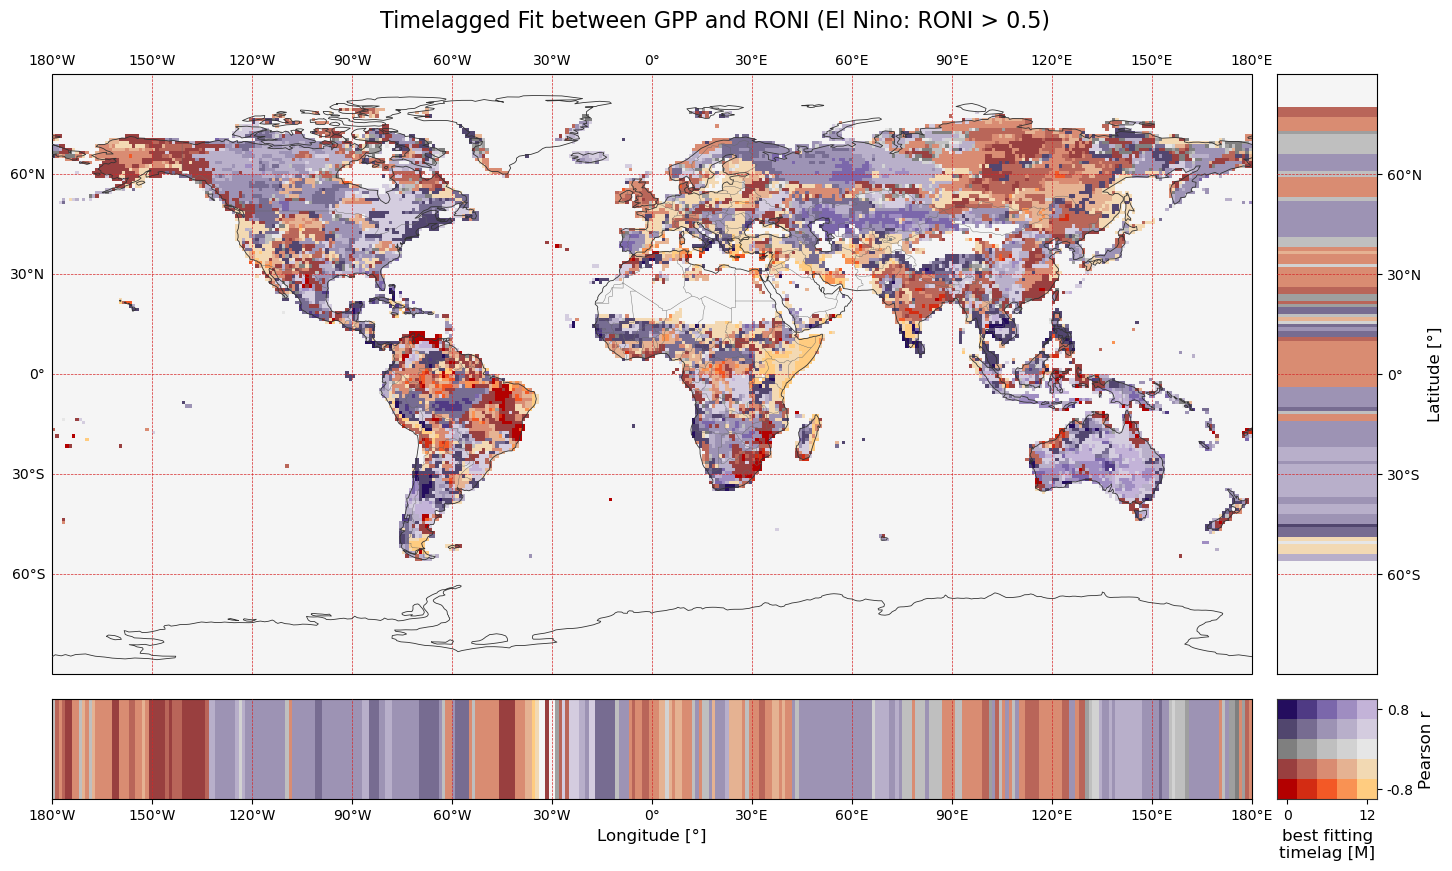

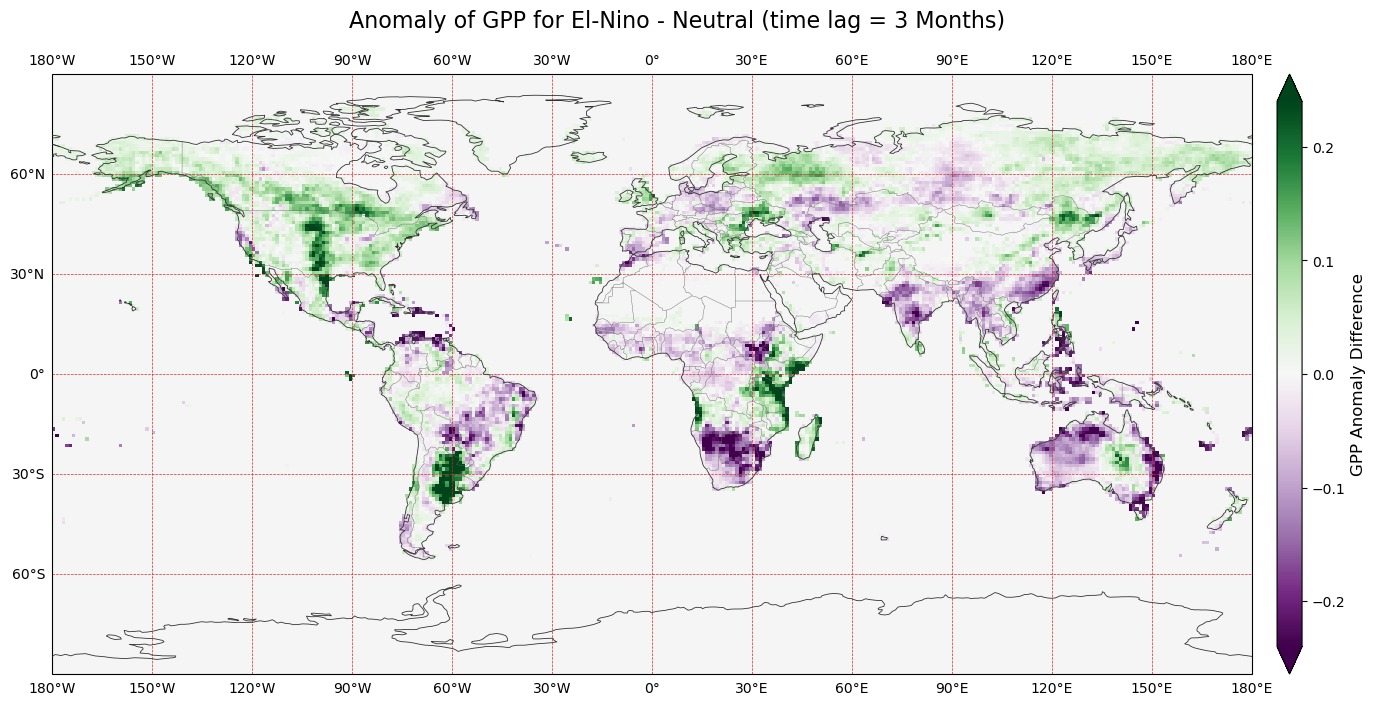

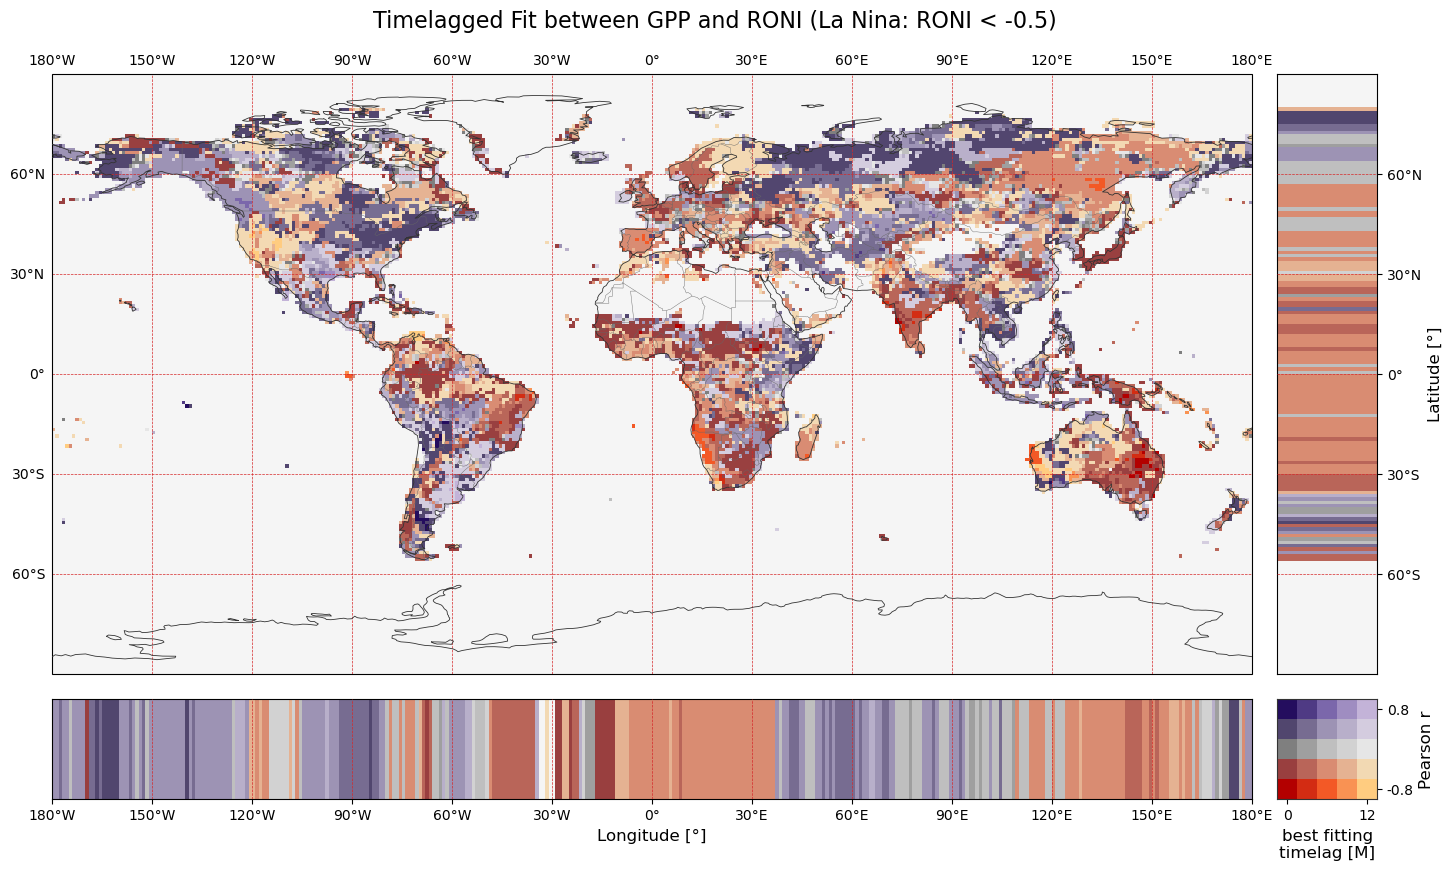

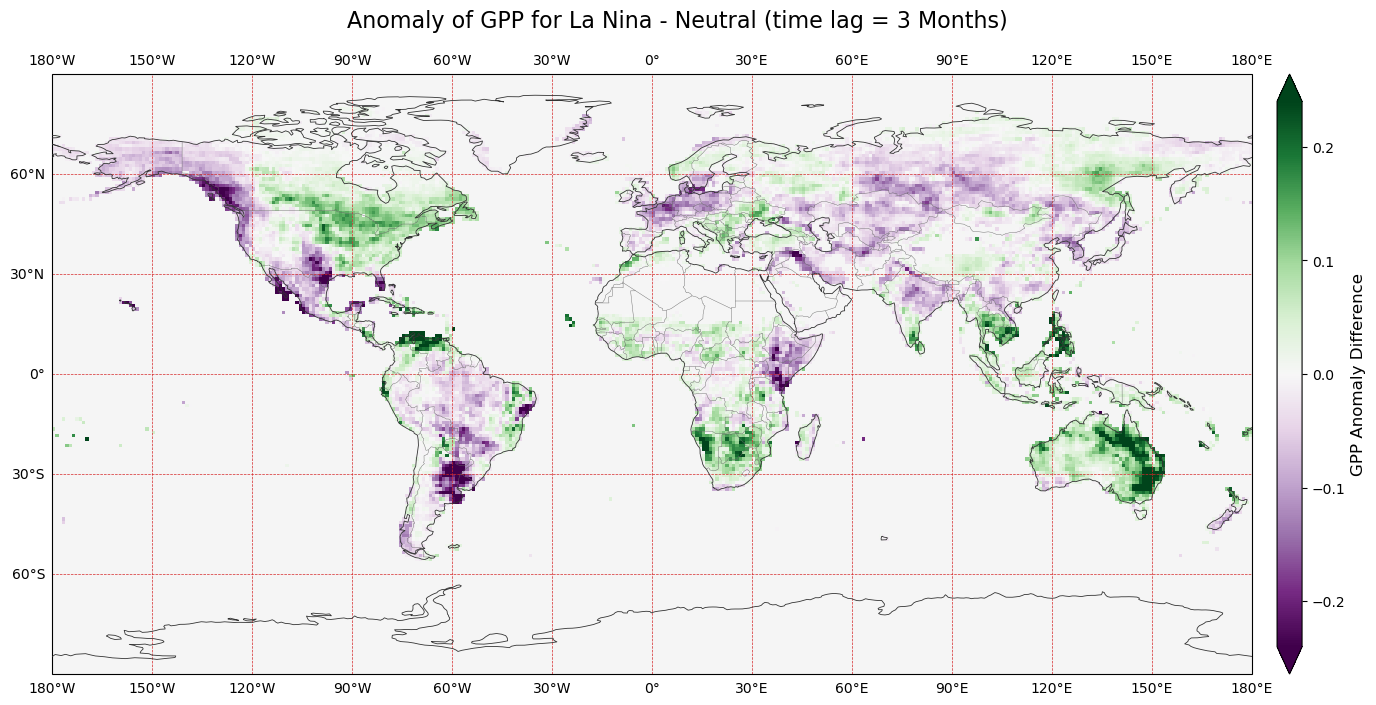

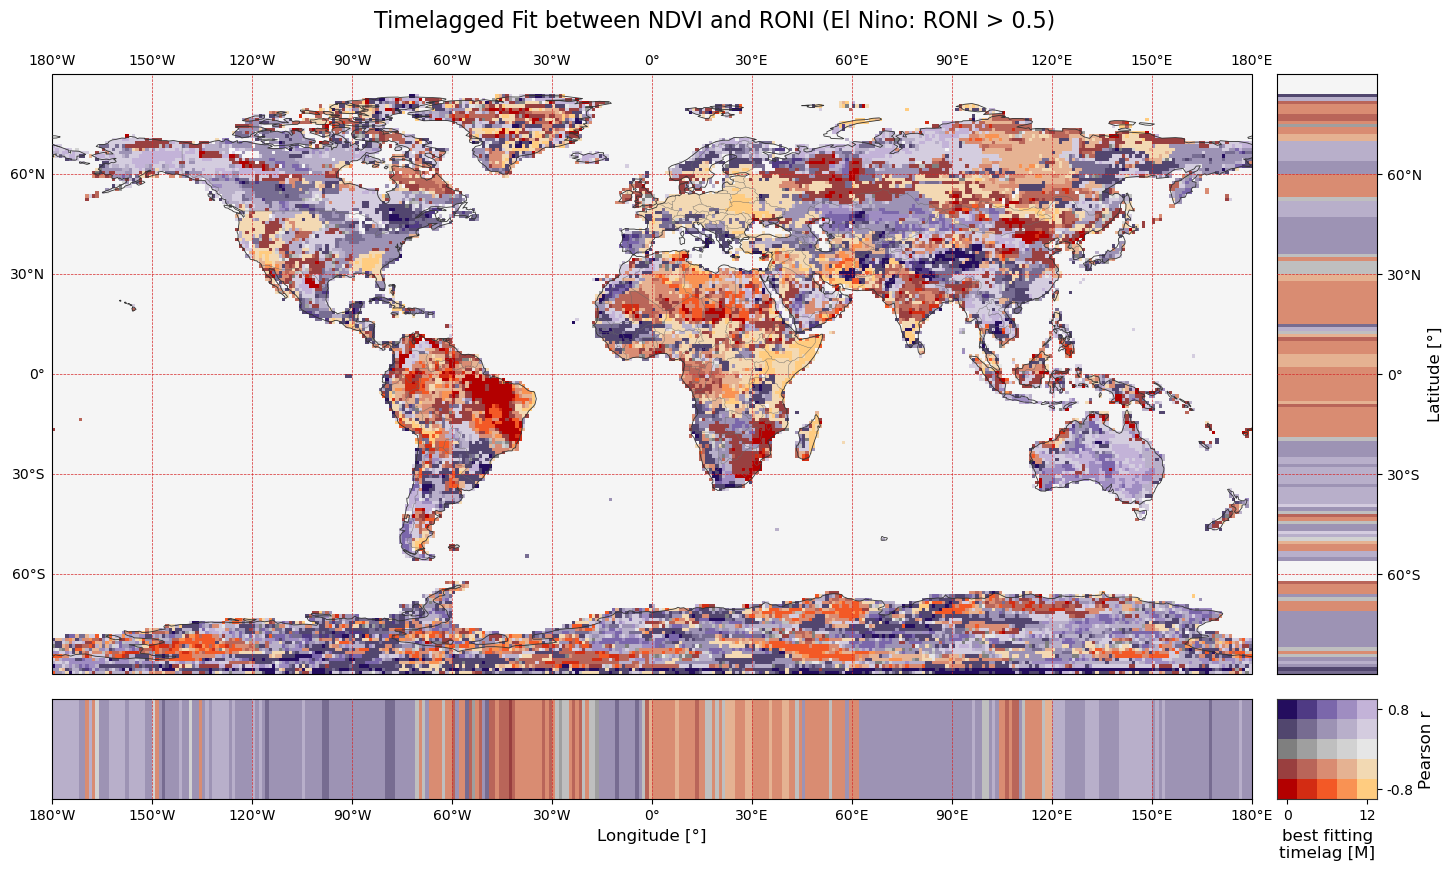

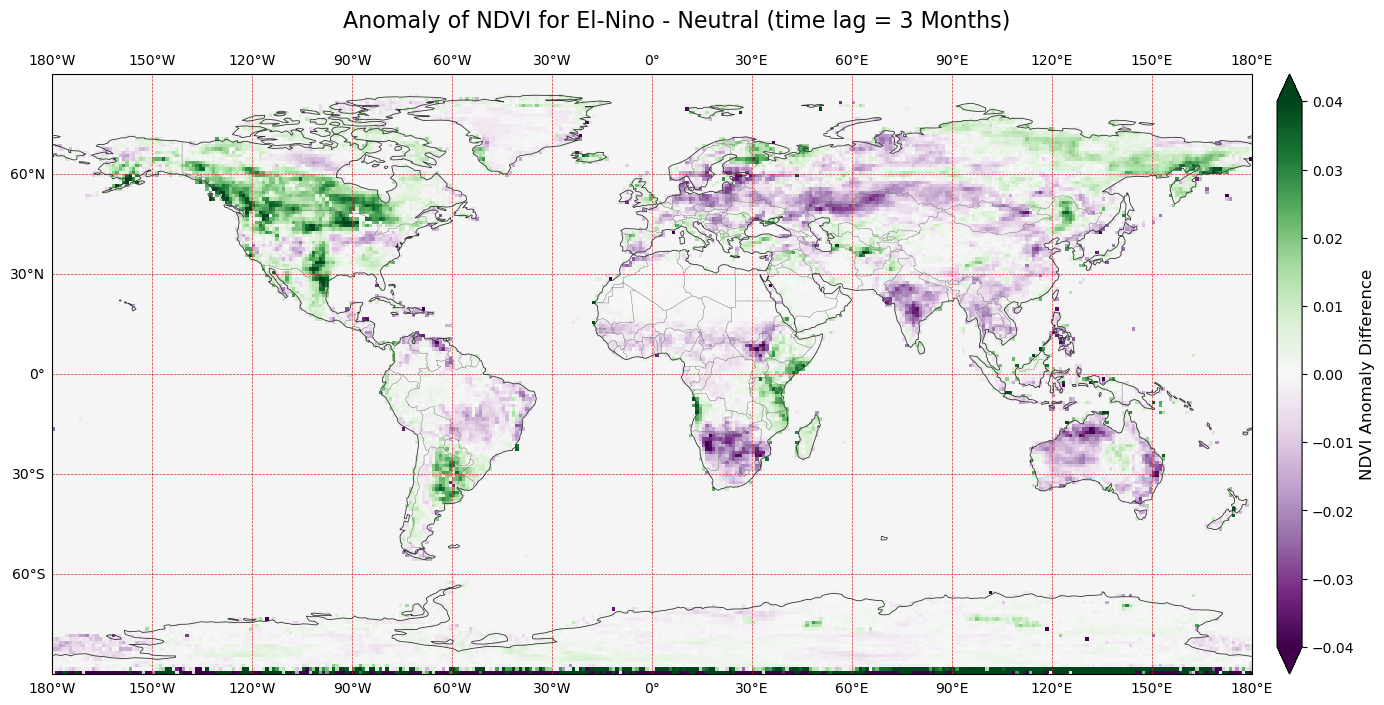

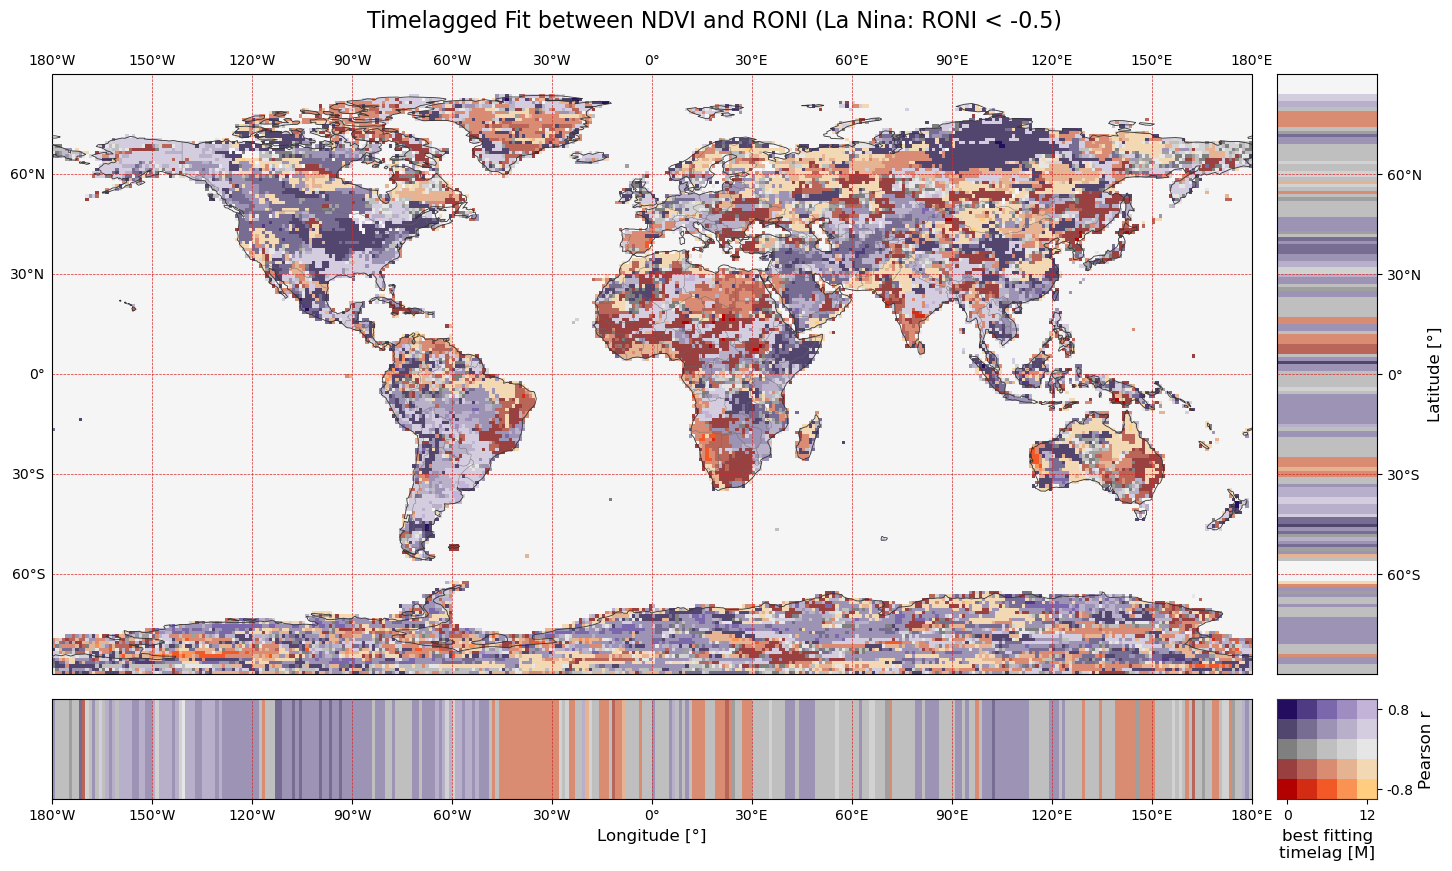

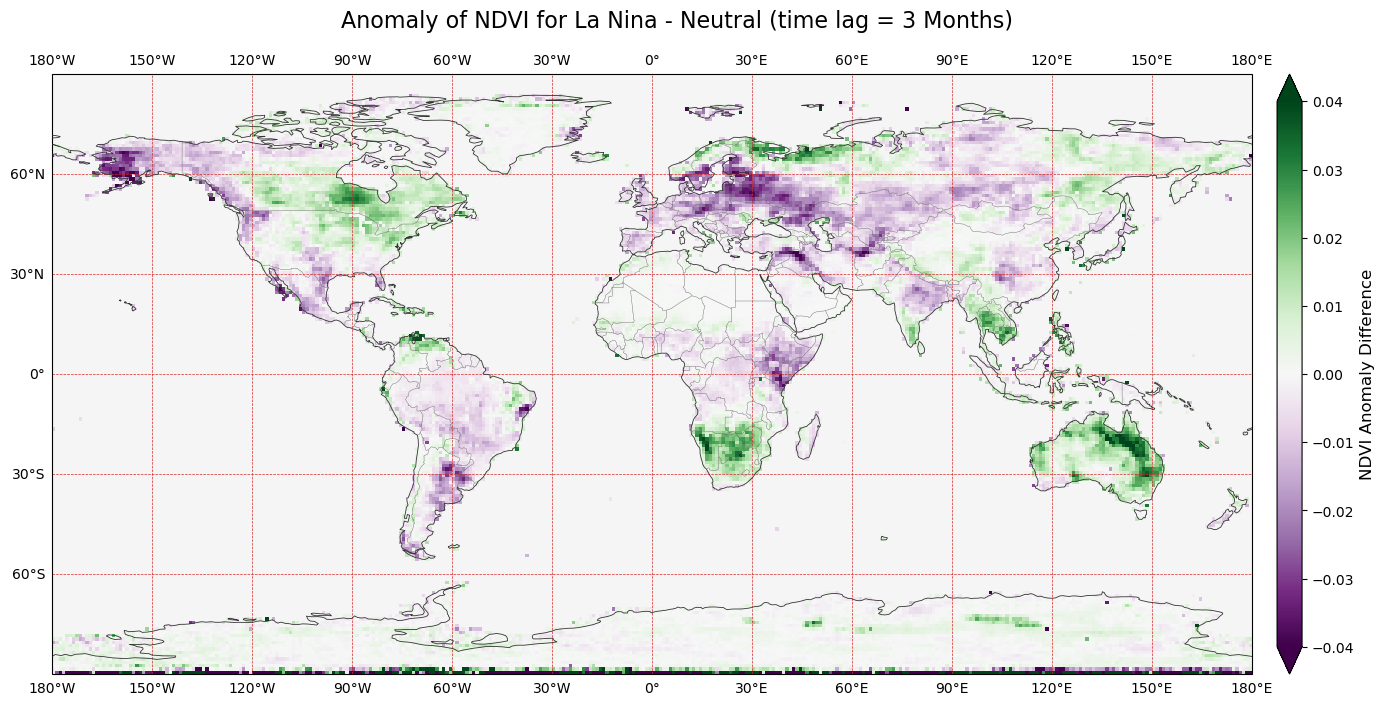

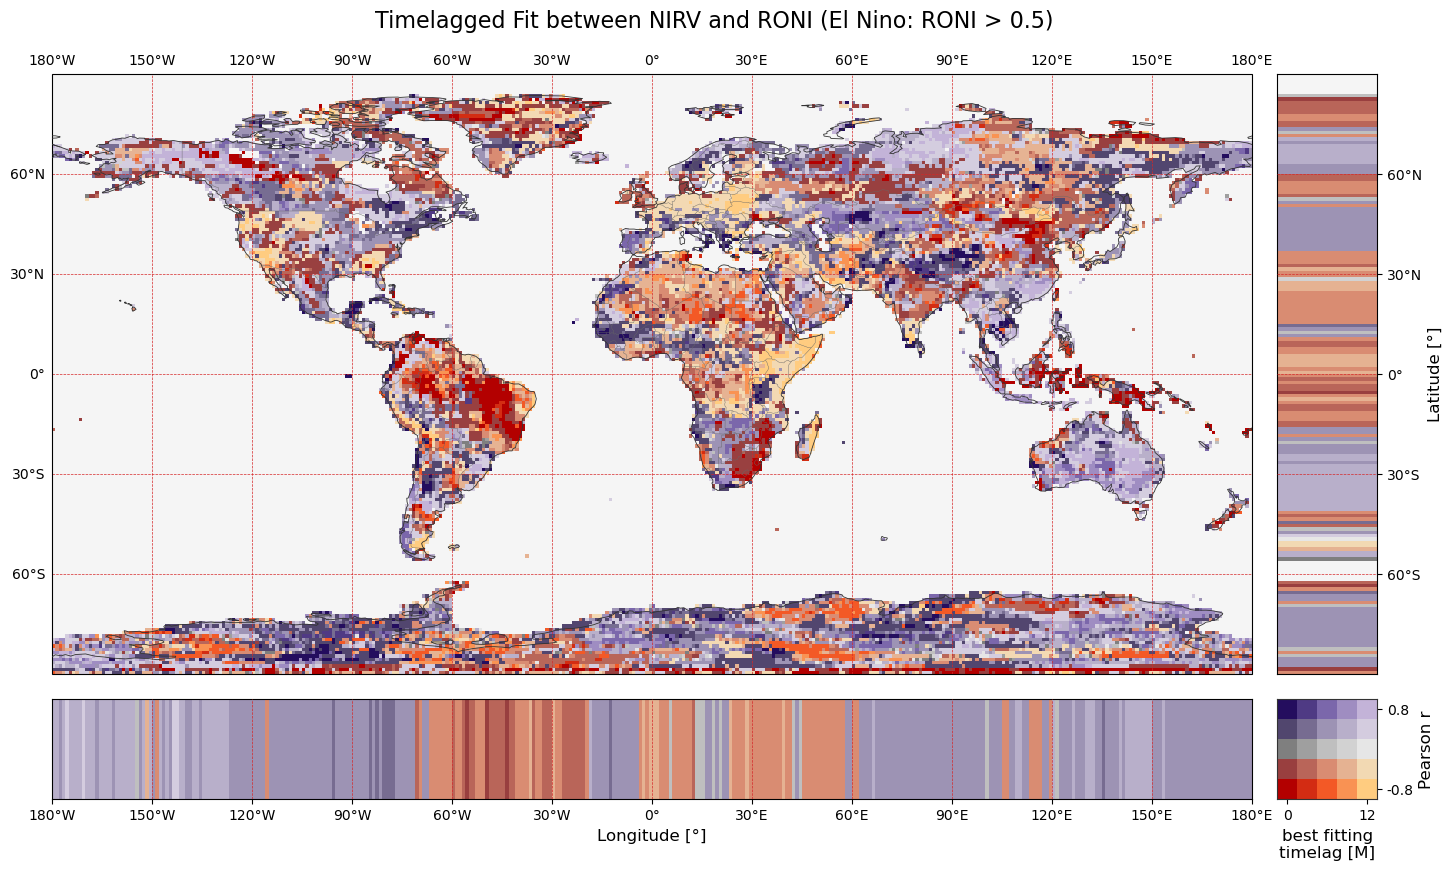

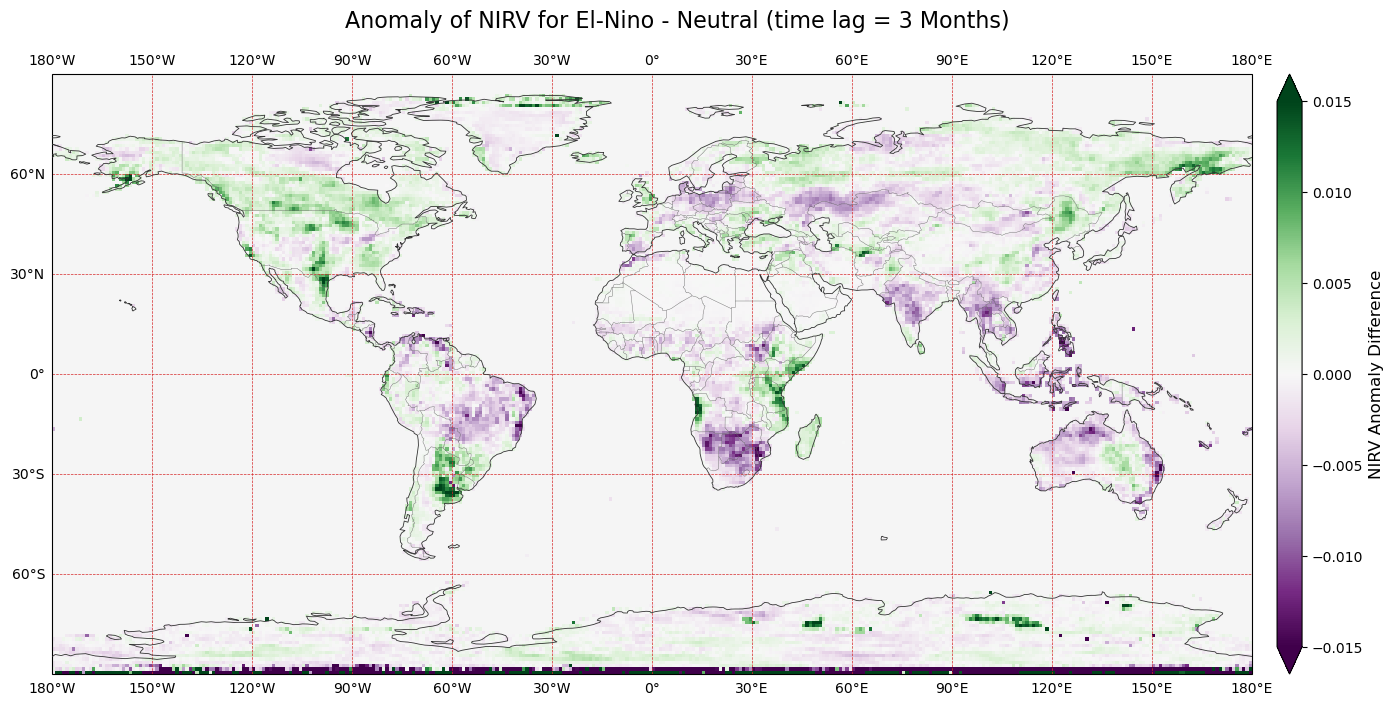

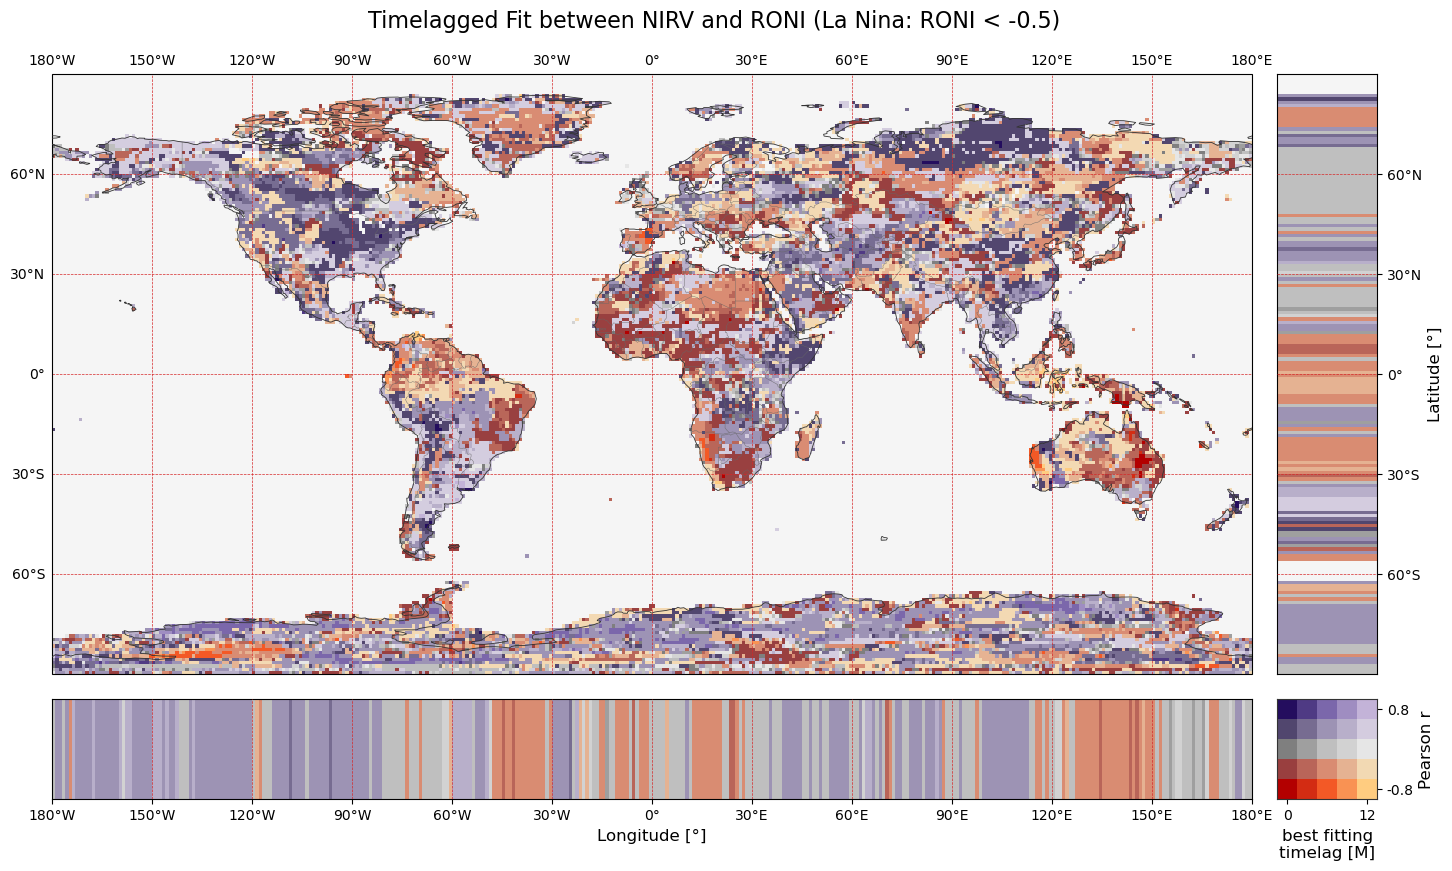

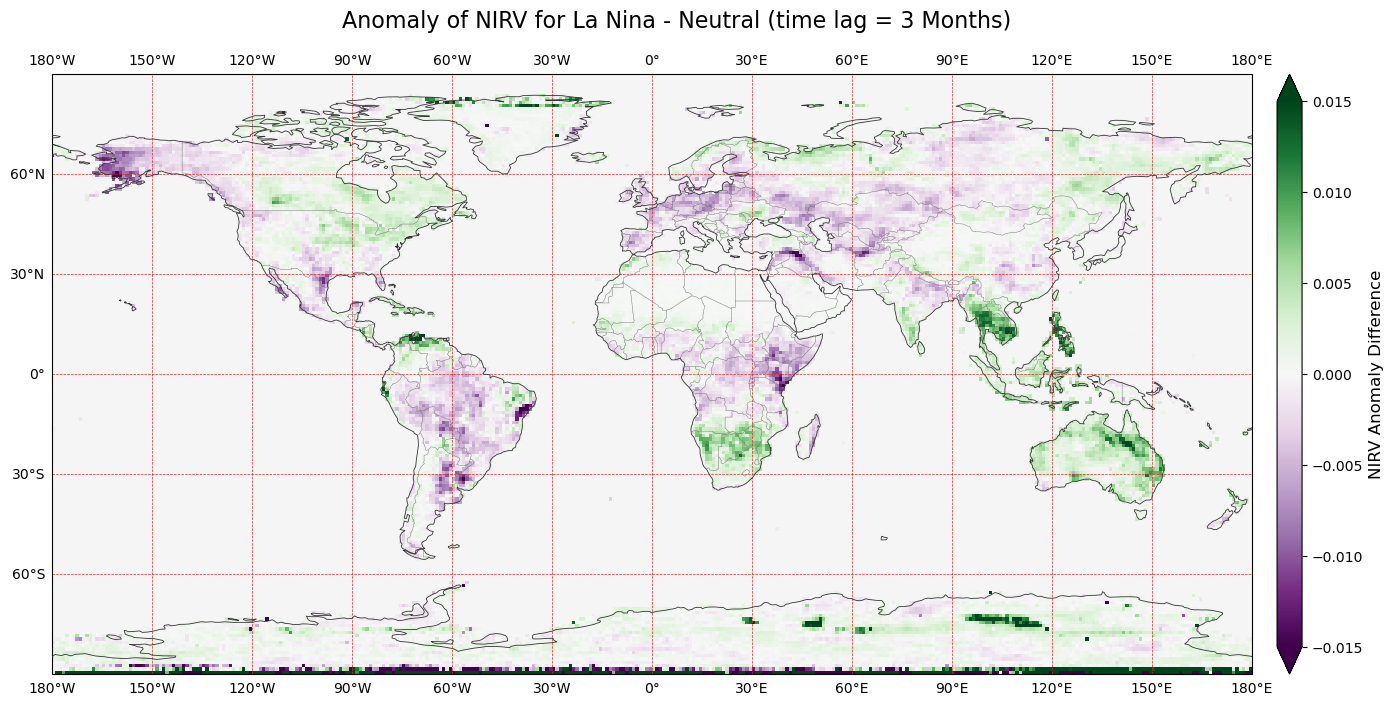

In [9]:
names = ["global_gpp_phases", "global_ndvi_phases", "global_nirv_phases"]
metrics = ["GPP", "NDVI", "NIRV"]
vrange = [0.24, 0.04, 0.015]
subfolder = "phase"
if not os.path.exists(f"{plot_folder}/{subfolder}/bivariate"):
    os.makedirs(f"{plot_folder}/{subfolder}/bivariate")
if not os.path.exists(f"{plot_folder}/{subfolder}/anomaly"):
    os.makedirs(f"{plot_folder}/{subfolder}/anomaly")
for i, name in enumerate(names):
    ds = xr.open_dataset(f"{data_folder}/{name}.nc")
    fig, ax, legend = plot_bivariate_raster(ds=ds.sel(phase="el_nino"), 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI (El Nino: RONI > 0.5)",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/bivariate/{name}_el_nino.png", dpi=100)
    
    fig, ax, cax = plot_raster(ds = ds.sel(phase="el_nino"),
            var = "phase_minus_neutral",
            cmap=plt.cm.PRGn,
            name_var=f"{metrics[i]} Anomaly Difference",
            title=f"Anomaly of {metrics[i]} for El-Nino - Neutral (time lag = 3 Months)",
            vmin=-vrange[i],
            vmax=vrange[i])
    plt.savefig(f"{plot_folder}/{subfolder}/anomaly/{name}_el_nino_anomaly.png", dpi=100)
    
    fig, ax, legend = plot_bivariate_raster(ds=ds.sel(phase="la_nina"), 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI (La Nina: RONI < -0.5)",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/bivariate/{name}_la_nina.png", dpi=100)

    fig, ax, cax = plot_raster(ds = ds.sel(phase="la_nina"),
        var = "phase_minus_neutral",
        cmap=plt.cm.PRGn,
        name_var=f"{metrics[i]} Anomaly Difference",
        title=f"Anomaly of {metrics[i]} for La Nina - Neutral (time lag = 3 Months)",
        vmin=-vrange[i],
        vmax=vrange[i])
    plt.savefig(f"{plot_folder}/{subfolder}/anomaly/{name}_la_nina_anomaly.png", dpi=100)

### REGIONAL PLOTS (five plots per region)

#### ARGENTINA

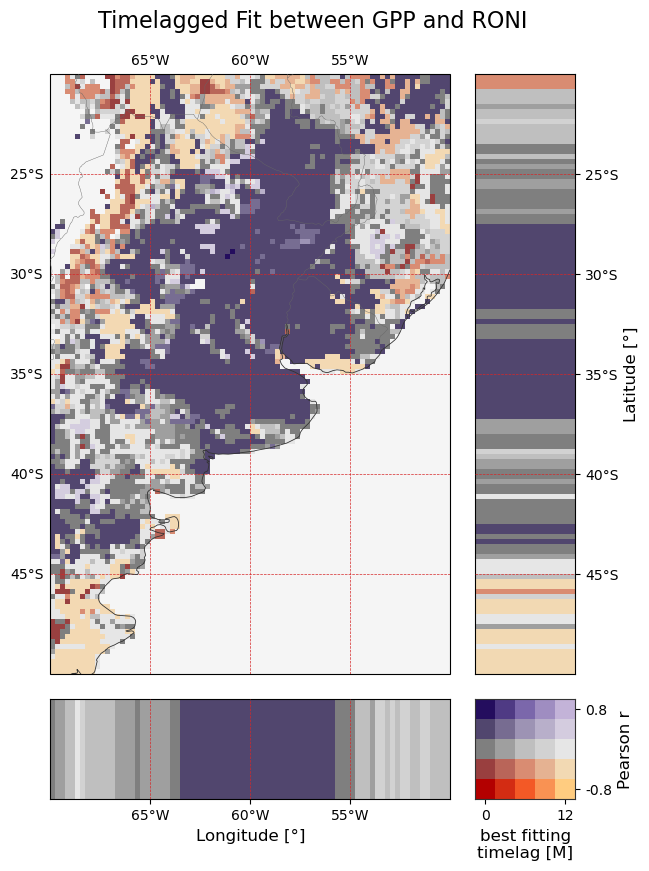

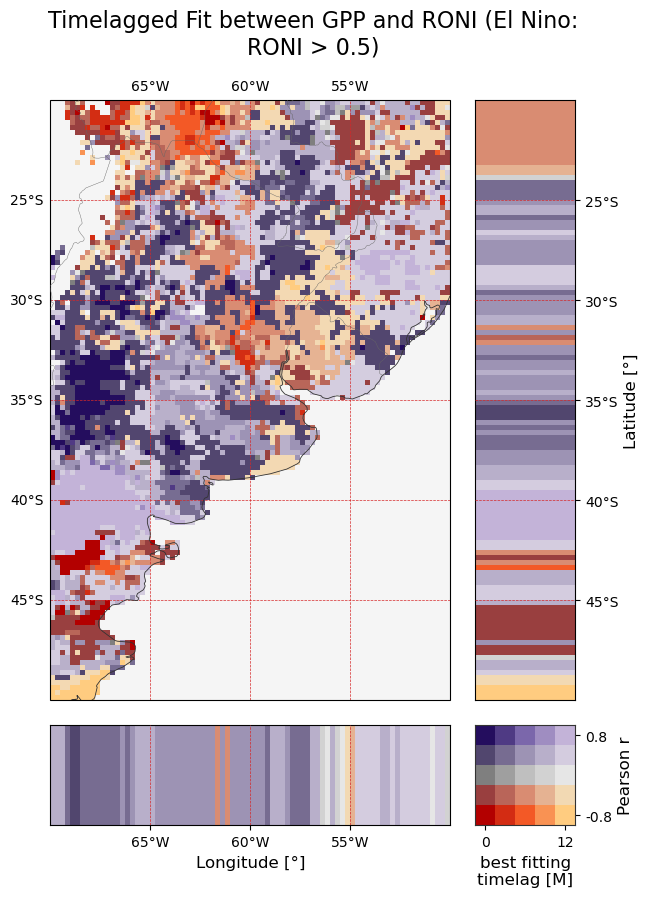

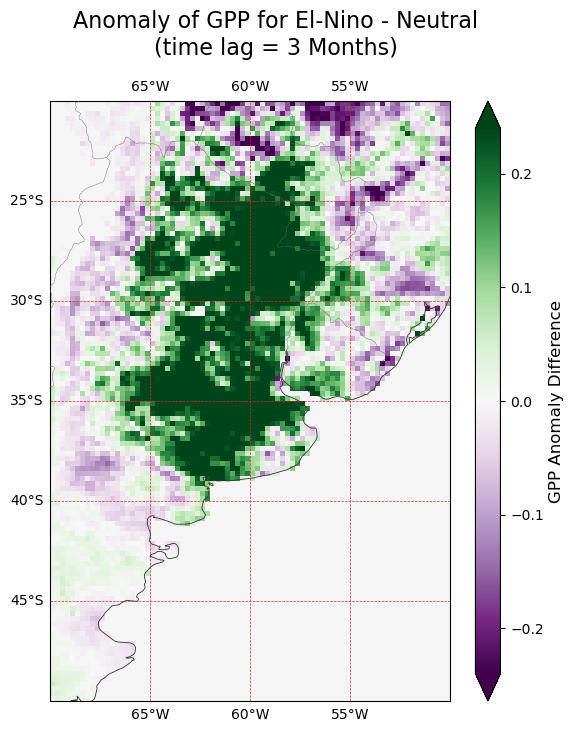

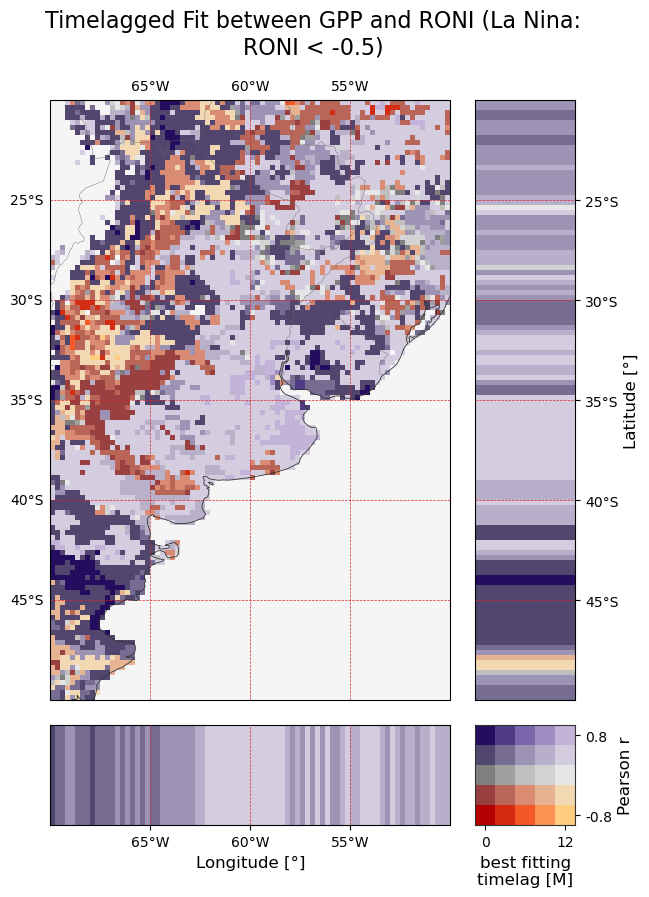

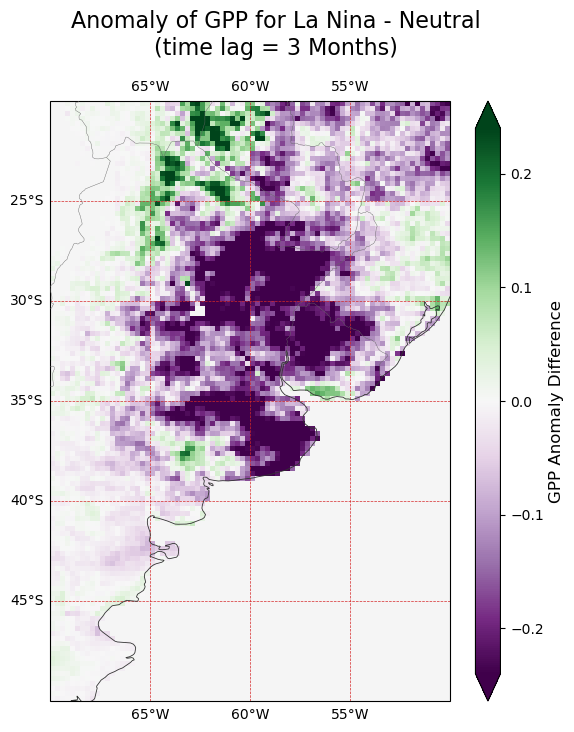

In [10]:
names = ["Argentina_gpp_R+lag"]
metrics = ["GPP"]
subfolder = "lag"
lat_extent = [-50, -20]
lon_extent = [-70, -50]
if not os.path.exists(f"{plot_folder}/{subfolder}/"):
    os.makedirs(f"{plot_folder}/{subfolder}")
for i, name_lag in enumerate(names):
    ds = xr.open_dataset(f"{data_folder}/{name_lag}.nc")
    fig, ax, legend = plot_bivariate_raster(ds=ds, 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/{name_lag}.png", dpi=100)

names = ["Argentina_gpp_phases"]
metrics = ["GPP"]
vrange = [0.24, 0.04, 0.015]
subfolder = "phase"
if not os.path.exists(f"{plot_folder}/{subfolder}/bivariate"):
    os.makedirs(f"{plot_folder}/{subfolder}/bivariate")
if not os.path.exists(f"{plot_folder}/{subfolder}/anomaly"):
    os.makedirs(f"{plot_folder}/{subfolder}/anomaly")
figs = []
for i, name in enumerate(names):
    ds = xr.open_dataset(f"{data_folder}/{name}.nc")
    fig, ax, legend = plot_bivariate_raster(ds=ds.sel(phase="el_nino"), 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI (El Nino: RONI > 0.5)",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    figs.append(fig)
    plt.savefig(f"{plot_folder}/{subfolder}/bivariate/{name}_el_nino.png", dpi=100)
    
    fig, ax, cax = plot_raster(ds = ds.sel(phase="el_nino"),
            var = "phase_minus_neutral",
            cmap=plt.cm.PRGn,
            name_var=f"{metrics[i]} Anomaly Difference",
            title=f"Anomaly of {metrics[i]} for El-Nino - Neutral (time lag = 3 Months)",
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
            vmin=-vrange[i],
            vmax=vrange[i])
    plt.savefig(f"{plot_folder}/{subfolder}/anomaly/{name}_el_nino_anomaly.png", dpi=100)
    
    fig, ax, legend = plot_bivariate_raster(ds=ds.sel(phase="la_nina"), 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI (La Nina: RONI < -0.5)",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    figs.append(fig)
    plt.savefig(f"{plot_folder}/{subfolder}/bivariate/{name}_la_nina.png", dpi=100)

    fig, ax, cax = plot_raster(ds = ds.sel(phase="la_nina"),
        var = "phase_minus_neutral",
        cmap=plt.cm.PRGn,
        name_var=f"{metrics[i]} Anomaly Difference",
        title=f"Anomaly of {metrics[i]} for La Nina - Neutral (time lag = 3 Months)",
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
        vmin=-vrange[i],
        vmax=vrange[i])
    plt.savefig(f"{plot_folder}/{subfolder}/anomaly/{name}_la_nina_anomaly.png", dpi=100)
    figs.append(fig)

# Stitch regional images into one figure
paths = [f"{plot_folder}/lag/{name_lag}.png", 
         f"{plot_folder}/{subfolder}/anomaly/{name}_el_nino_anomaly.png", 
         f"{plot_folder}/{subfolder}/anomaly/{name}_la_nina_anomaly.png"]
imgs = [Image.open(p) for p in paths]

# Calculate exact canvas dimensions (no resizing)
total_width = sum(img.width for img in imgs)
max_height = max(img.height for img in imgs)

# Use "RGBA" with (0, 0, 0, 0) for transparent background, or "RGB" with (255, 255, 255) for white
combined = Image.new("RGBA", (total_width, max_height), (255, 255, 255, 255))

x_offset = 0
for img in imgs:
    combined.paste(img, (x_offset, 0))
    x_offset += img.width

# Preserve original DPI metadata if present
dpi = imgs[0].info.get("dpi", (300, 300))
combined.save(f"{plot_folder}/Argentina_combined.png", dpi=dpi, compress_level=6)

#### Southern Africa

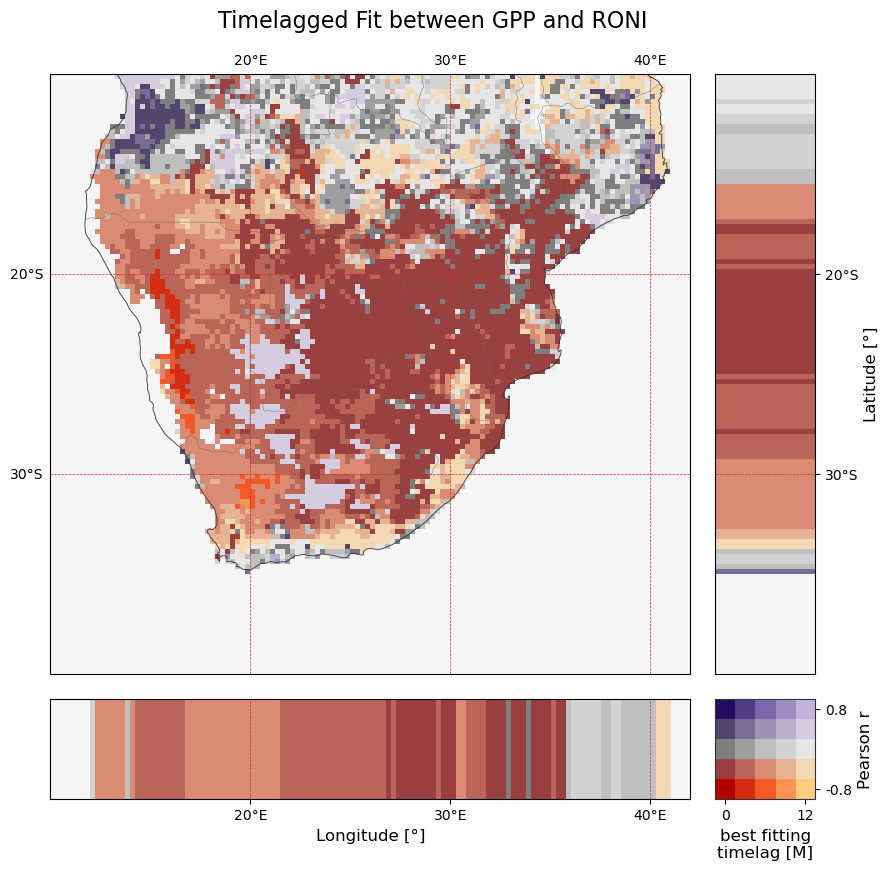

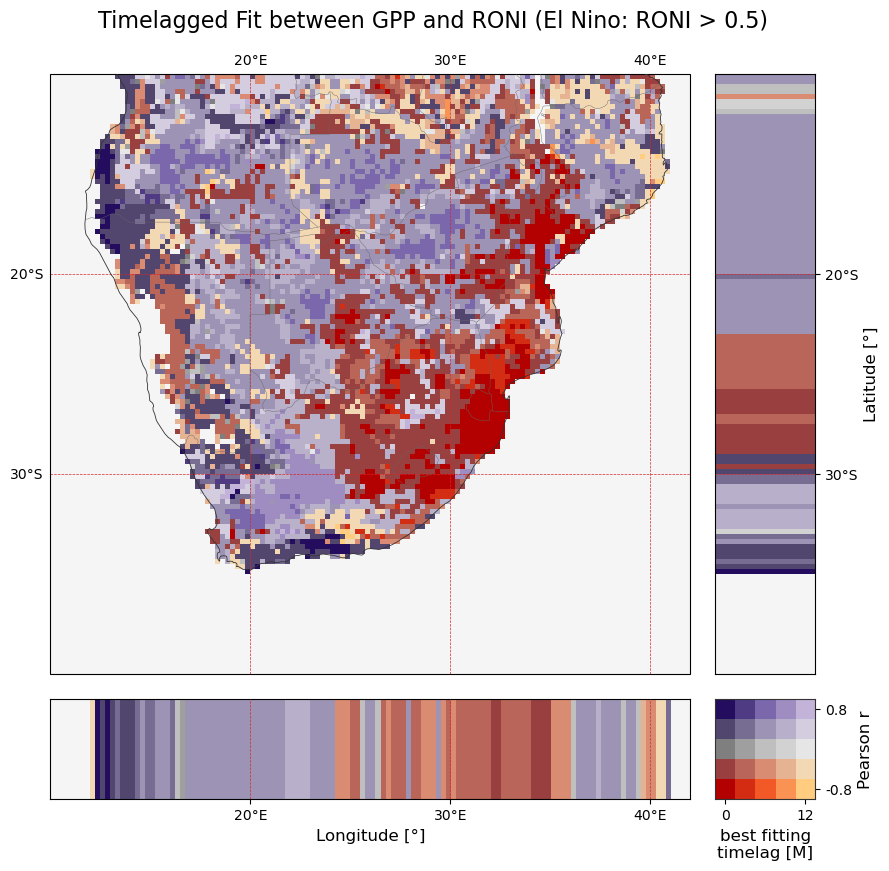

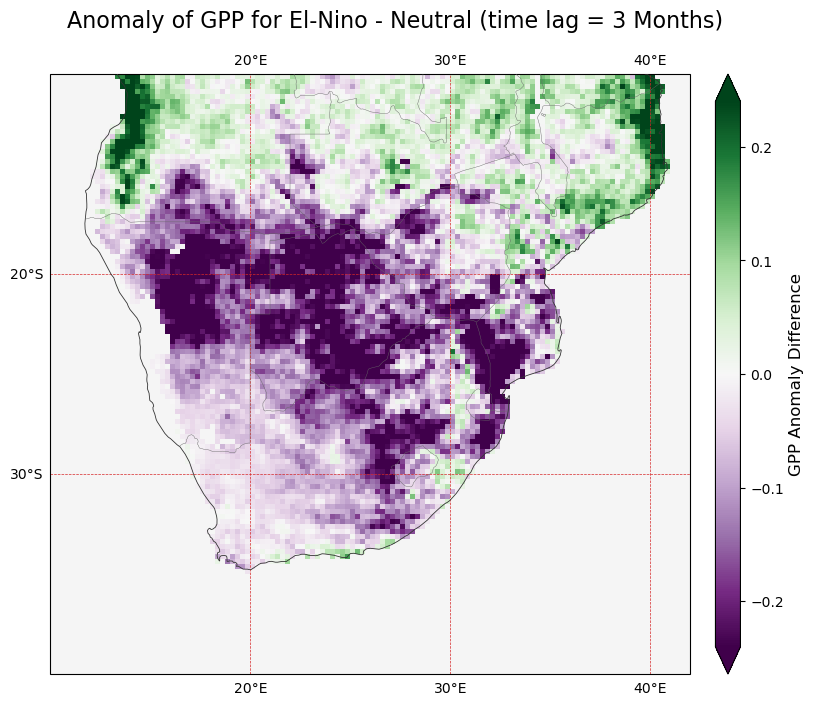

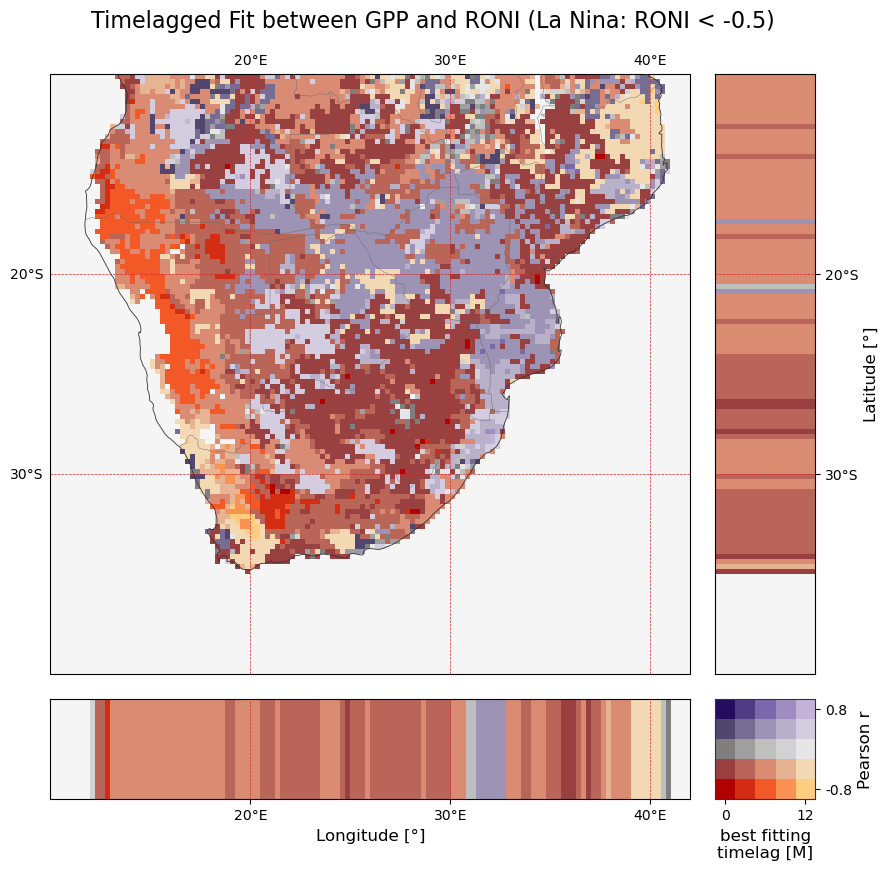

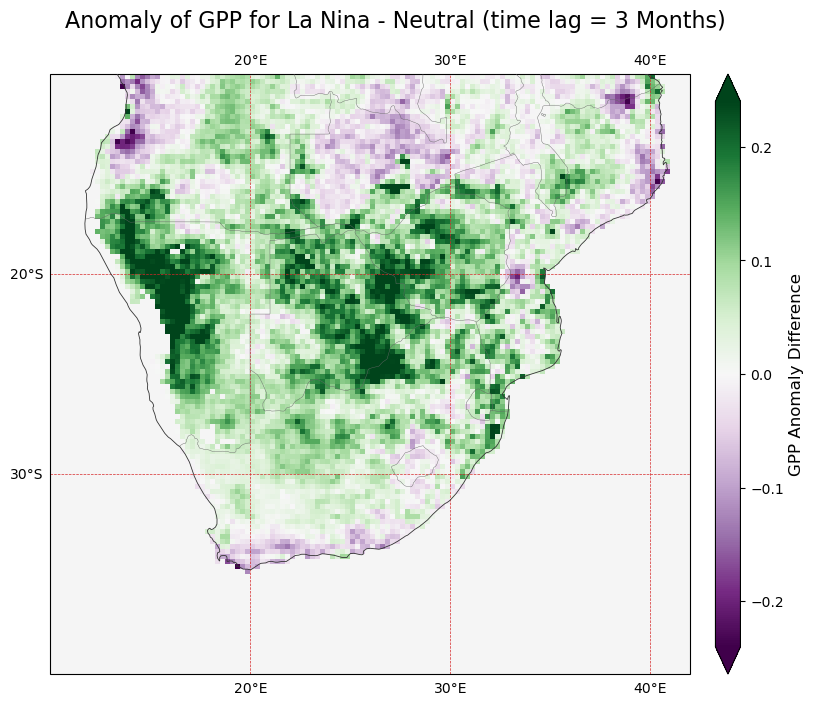

In [11]:
names = ["South-Africa_gpp_R+lag"]
metrics = ["GPP"]
subfolder = "lag"
lat_extent = [-40, -10]
lon_extent = [10,42]
if not os.path.exists(f"{plot_folder}/{subfolder}/"):
    os.makedirs(f"{plot_folder}/{subfolder}")
for i, name_lag in enumerate(names):
    ds = xr.open_dataset(f"{data_folder}/{name_lag}.nc")
    fig, ax, legend = plot_bivariate_raster(ds=ds, 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/{name_lag}.png", dpi=100)

names = ["South-Africa_gpp_phases"]
metrics = ["GPP"]
vrange = [0.24, 0.04, 0.015]
subfolder = "phase"
if not os.path.exists(f"{plot_folder}/{subfolder}/bivariate"):
    os.makedirs(f"{plot_folder}/{subfolder}/bivariate")
if not os.path.exists(f"{plot_folder}/{subfolder}/anomaly"):
    os.makedirs(f"{plot_folder}/{subfolder}/anomaly")
for i, name in enumerate(names):
    ds = xr.open_dataset(f"{data_folder}/{name}.nc")
    fig, ax, legend = plot_bivariate_raster(ds=ds.sel(phase="el_nino"), 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI (El Nino: RONI > 0.5)",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/bivariate/{name}_el_nino.png", dpi=100)
    
    fig, ax, cax = plot_raster(ds = ds.sel(phase="el_nino"),
            var = "phase_minus_neutral",
            cmap=plt.cm.PRGn,
            name_var=f"{metrics[i]} Anomaly Difference",
            title=f"Anomaly of {metrics[i]} for El-Nino - Neutral (time lag = 3 Months)",
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
            vmin=-vrange[i],
            vmax=vrange[i])
    plt.savefig(f"{plot_folder}/{subfolder}/anomaly/{name}_el_nino_anomaly.png", dpi=100)
    
    fig, ax, legend = plot_bivariate_raster(ds=ds.sel(phase="la_nina"), 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI (La Nina: RONI < -0.5)",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/bivariate/{name}_la_nina.png", dpi=100)

    fig, ax, cax = plot_raster(ds = ds.sel(phase="la_nina"),
        var = "phase_minus_neutral",
        cmap=plt.cm.PRGn,
        name_var=f"{metrics[i]} Anomaly Difference",
        title=f"Anomaly of {metrics[i]} for La Nina - Neutral (time lag = 3 Months)",
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
        vmin=-vrange[i],
        vmax=vrange[i])
    plt.savefig(f"{plot_folder}/{subfolder}/anomaly/{name}_la_nina_anomaly.png", dpi=100)

# Stitch regional images into one figure
paths = [f"{plot_folder}/lag/{name_lag}.png", 
         f"{plot_folder}/{subfolder}/anomaly/{name}_el_nino_anomaly.png", 
         f"{plot_folder}/{subfolder}/anomaly/{name}_la_nina_anomaly.png"]
imgs = [Image.open(p) for p in paths]

# Calculate exact canvas dimensions (no resizing)
total_width = sum(img.width for img in imgs)
max_height = max(img.height for img in imgs)

# Use "RGBA" with (0, 0, 0, 0) for transparent background, or "RGB" with (255, 255, 255) for white
combined = Image.new("RGBA", (total_width, max_height), (255, 255, 255, 255))

x_offset = 0
for img in imgs:
    combined.paste(img, (x_offset, 0))
    x_offset += img.width

# Preserve original DPI metadata if present
dpi = imgs[0].info.get("dpi", (300, 300))
combined.save(f"{plot_folder}/Southern-Africa_combined.png", dpi=dpi, compress_level=6)

#### Eastern Africa

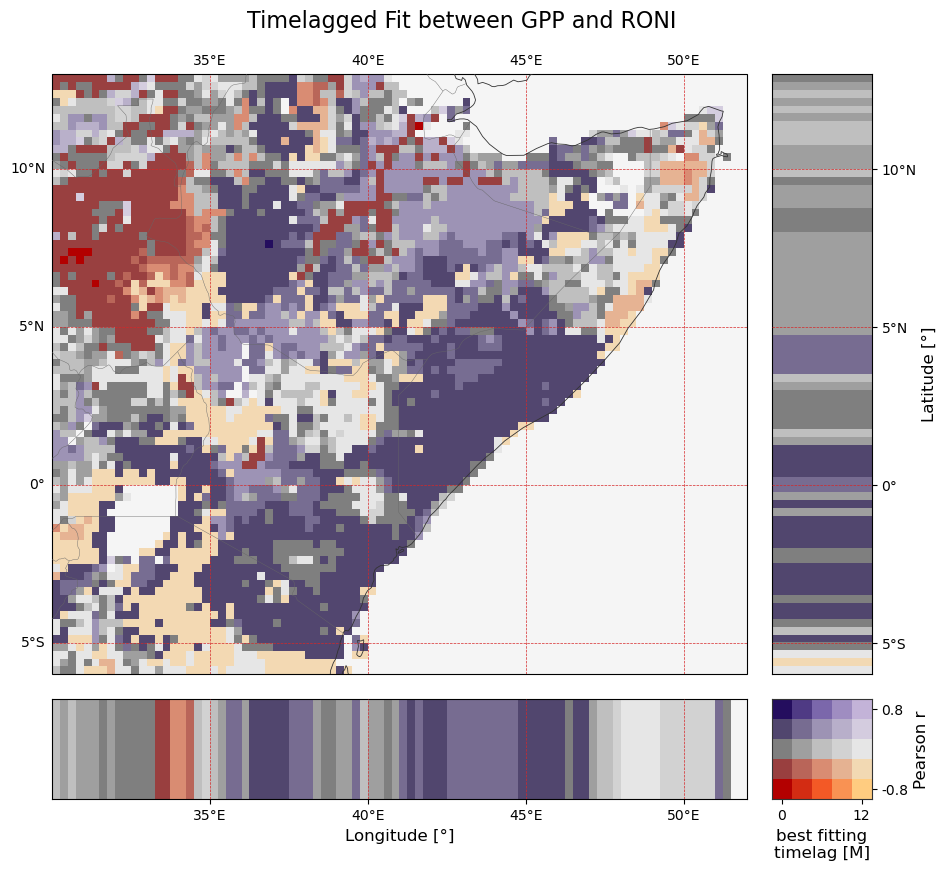

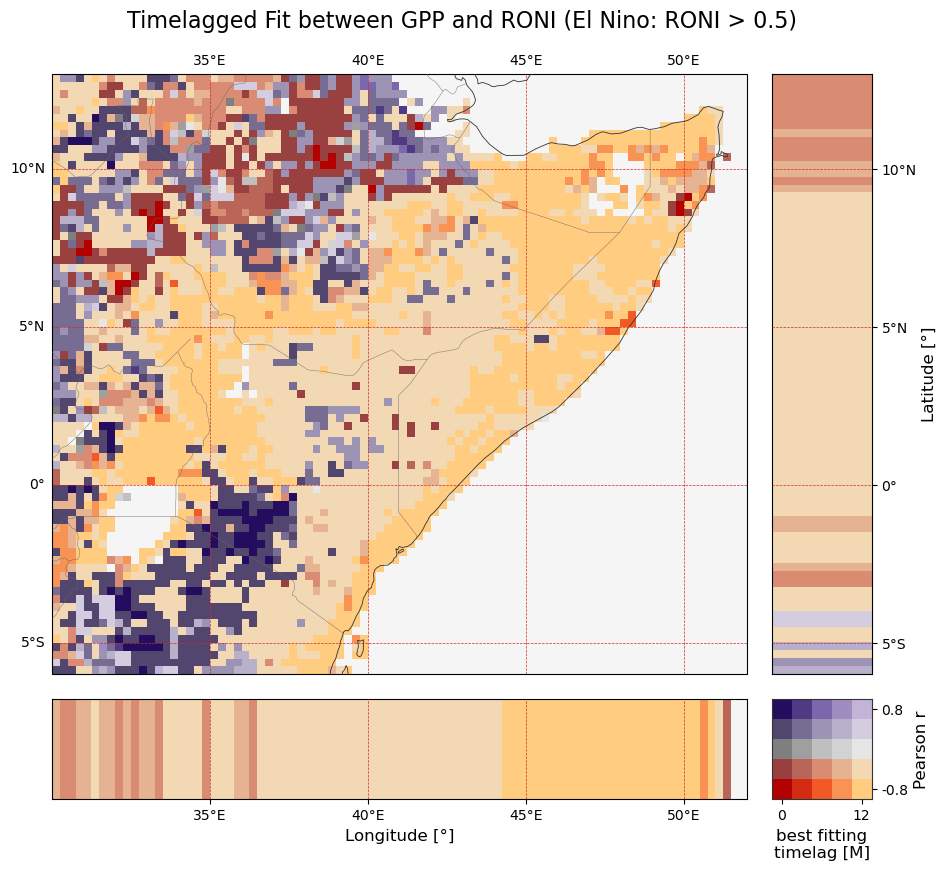

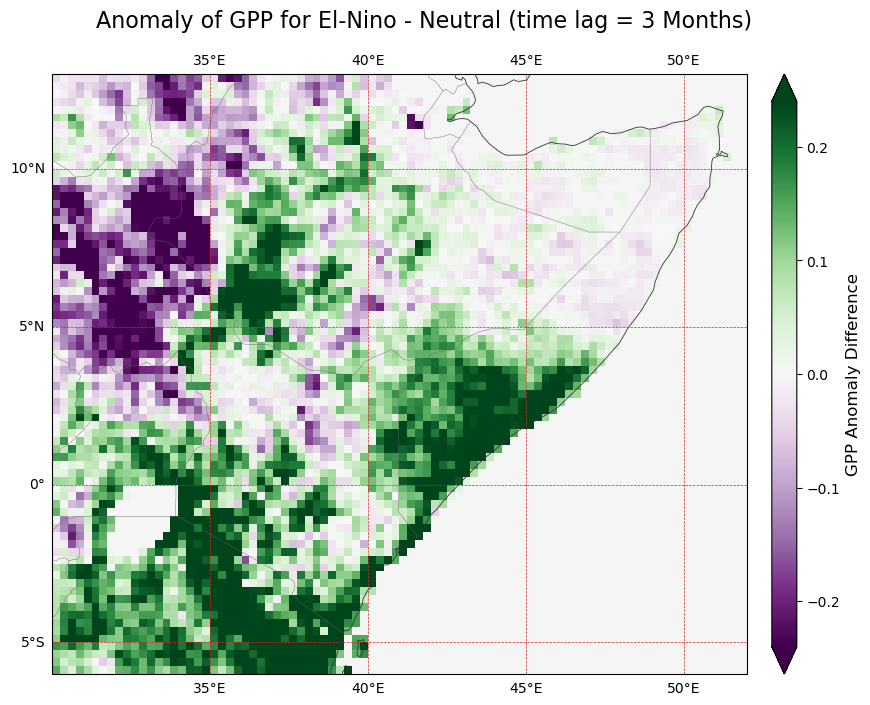

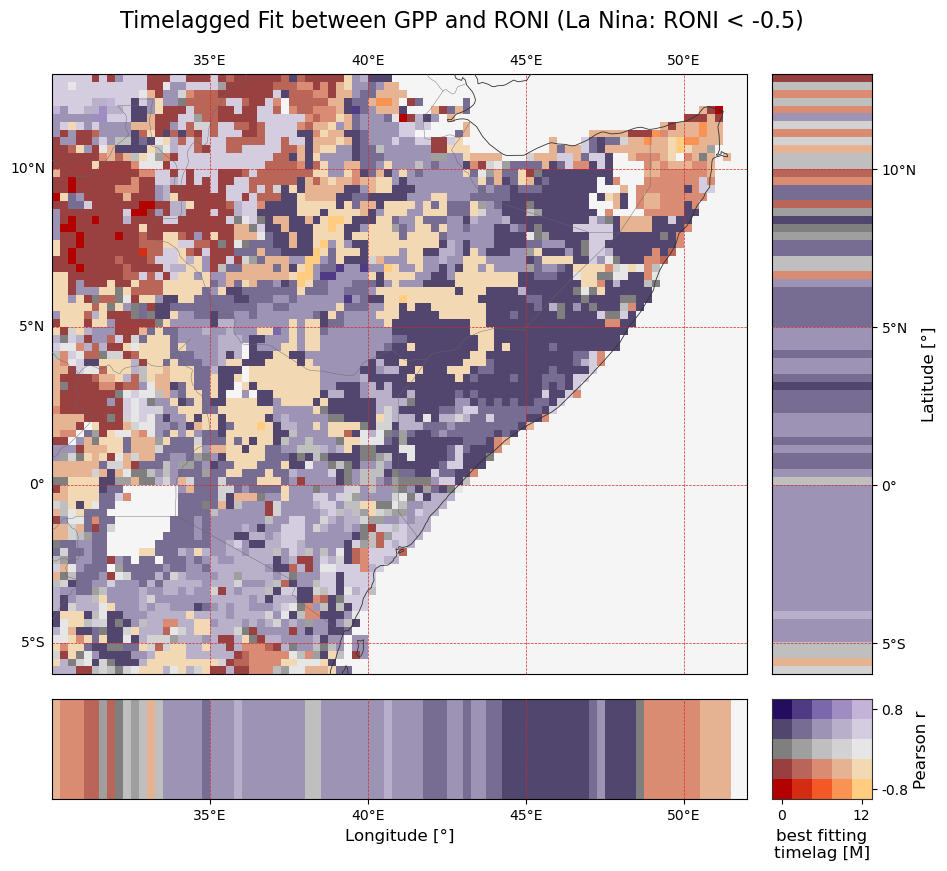

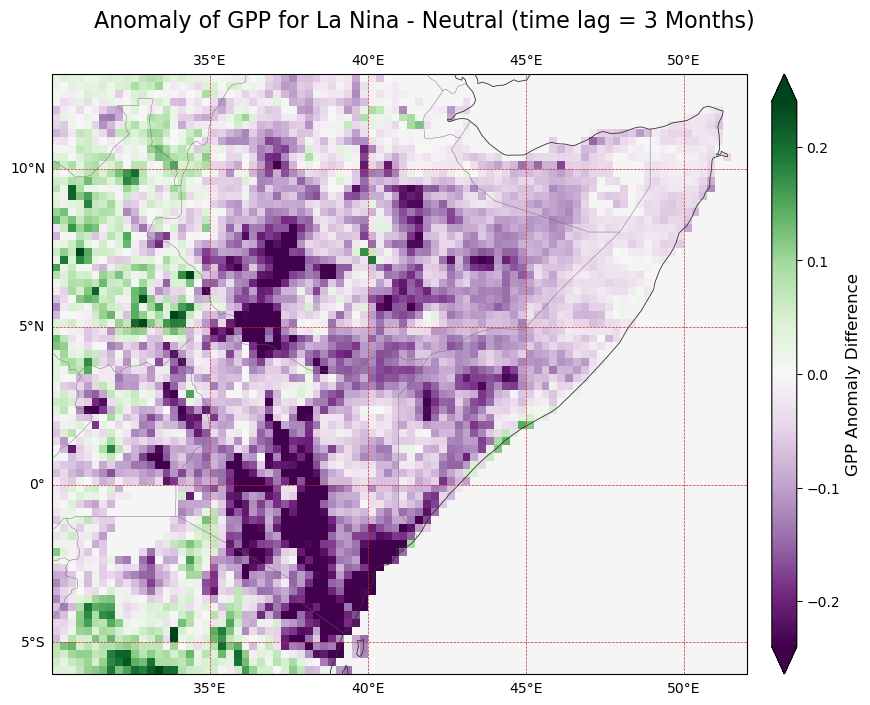

In [12]:
names = ["East-Africa_gpp_R+lag"]
metrics = ["GPP"]
subfolder = "lag"
lat_extent = [-6,13]
lon_extent = [30, 52]
if not os.path.exists(f"{plot_folder}/{subfolder}/"):
    os.makedirs(f"{plot_folder}/{subfolder}")
for i, name_lag in enumerate(names):
    ds = xr.open_dataset(f"{data_folder}/{name_lag}.nc")
    fig, ax, legend = plot_bivariate_raster(ds=ds, 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/{name_lag}.png", dpi=100)

names = ["East-Africa_gpp_phases"]
metrics = ["GPP"]
vrange = [0.24, 0.04, 0.015]
subfolder = "phase"
if not os.path.exists(f"{plot_folder}/{subfolder}/bivariate"):
    os.makedirs(f"{plot_folder}/{subfolder}/bivariate")
if not os.path.exists(f"{plot_folder}/{subfolder}/anomaly"):
    os.makedirs(f"{plot_folder}/{subfolder}/anomaly")
for i, name in enumerate(names):
    ds = xr.open_dataset(f"{data_folder}/{name}.nc")
    fig, ax, legend = plot_bivariate_raster(ds=ds.sel(phase="el_nino"), 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI (El Nino: RONI > 0.5)",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/bivariate/{name}_el_nino.png", dpi=100)
    
    fig, ax, cax = plot_raster(ds = ds.sel(phase="el_nino"),
            var = "phase_minus_neutral",
            cmap=plt.cm.PRGn,
            name_var=f"{metrics[i]} Anomaly Difference",
            title=f"Anomaly of {metrics[i]} for El-Nino - Neutral (time lag = 3 Months)",
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
            vmin=-vrange[i],
            vmax=vrange[i])
    plt.savefig(f"{plot_folder}/{subfolder}/anomaly/{name}_el_nino_anomaly.png", dpi=100)
    
    fig, ax, legend = plot_bivariate_raster(ds=ds.sel(phase="la_nina"), 
                                            var_x="lag_best", 
                                            var_y="r_best", 
                                            title=f"Timelagged Fit between {metrics[i]} and RONI (La Nina: RONI < -0.5)",
                                            ymin=-0.8, 
                                            ymax=0.8,
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
                                            name_y="Pearson r", 
                                            name_x="best fitting\ntimelag [M]",
                                            n_bins=5)
    plt.savefig(f"{plot_folder}/{subfolder}/bivariate/{name}_la_nina.png", dpi=100)

    fig, ax, cax = plot_raster(ds = ds.sel(phase="la_nina"),
        var = "phase_minus_neutral",
        cmap=plt.cm.PRGn,
        name_var=f"{metrics[i]} Anomaly Difference",
        title=f"Anomaly of {metrics[i]} for La Nina - Neutral (time lag = 3 Months)",
                                            lat_extent = lat_extent,
                                            lon_extent = lon_extent,
        vmin=-vrange[i],
        vmax=vrange[i])
    plt.savefig(f"{plot_folder}/{subfolder}/anomaly/{name}_la_nina_anomaly.png", dpi=100)

# Stitch regional images into one figure
paths = [f"{plot_folder}/lag/{name_lag}.png", 
         f"{plot_folder}/{subfolder}/anomaly/{name}_el_nino_anomaly.png", 
         f"{plot_folder}/{subfolder}/anomaly/{name}_la_nina_anomaly.png"]
imgs = [Image.open(p) for p in paths]

# Calculate exact canvas dimensions (no resizing)
total_width = sum(img.width for img in imgs)
max_height = max(img.height for img in imgs)

# Use "RGBA" with (0, 0, 0, 0) for transparent background, or "RGB" with (255, 255, 255) for white
combined = Image.new("RGBA", (total_width, max_height), (255, 255, 255, 255))

x_offset = 0
for img in imgs:
    combined.paste(img, (x_offset, 0))
    x_offset += img.width

# Preserve original DPI metadata if present
dpi = imgs[0].info.get("dpi", (300, 300))
combined.save(f"{plot_folder}/Eastern-Africa_combined.png", dpi=dpi, compress_level=6)

# PART 3: CREATE CAPTIVATING STORY

<hr>

# <a id='section7'></a><span style='color:DarkCyan'> 7. Share the link to your webstory </center> </span>

# [Dashboard Link](https://eoxhub-workspaces.github.io/preview-narratives/story/?storyurl=https%3A%2F%2FESA-eodashboards.github.io%2Feodashboard-narratives%2Fpr-preview%2Fpr-250%2FVegetation+response+to+atmoshere-ocean+circulations+.md)

<div class="alert alert-success" role="alert">

## SUBMIT YOUR RESULTS!
---------------------
Submit final version of your notebook in `sciencehub-challenges-user-data/outputs/[team-id]/` within Science Hub Challenge workspace. 
</div>

<br>


